# 2026 年中国研究生数学建模竞赛 F 题 · 问题三
## 算力约束下的风险可执行资源配置与结构转移

> **任务与结果口径**：给定预算 `C` 和上下文长度 `L_ctx`，在问题一、二已导出的证据边界内选择领域配比及 `N、D、Q_A`。本次保存的运行结果中，可执行配比只有 `p_risk`，因此数值结论均是**固定 `p_risk` 条件下**对 `N、D、Q_A` 的优化；它们不构成对任意领域配比的联合最优性证明。

### 证据链与模型边界

1. 问题一提供领域质量及正式导出的配比角色。本次虽读取了两份问题一 JSON，但角色台账只识别出可执行的 `p_risk`；没有把未导出的 `p_safe` 或 `p_measured` 补造成候选。
2. 问题二提供 SAED 参数、质量坐标桥和配比结构桥。其 `p_ref` 仅是归一化理论参考，**不参与**可执行决策。本次 `gamma_p` 未识别，主结果采用无尺度衰减的结构零假设 `gamma_p=0`；其他尺度函数仅用于人为设定的敏感性情景。
3. 质量治理从各配比自身的 `Q0_A(p)` 出发，以相对质量因子计入 Loss，避免把“配比改变所伴随的领域平均质量变化”重复写入性能。
4. 对三类质量成本和给定预算求数值最优配置，随后通过连续预算扫描与边界求根识别体制变化。边界表同时报告定位机制；数值状态边界不冒充 KKT 根。
5. 上下文长度、质量桥与人为尺度情景用于条件敏感性分析。问题二没有导出完整 Scaling 参数场景，本次不声称覆盖五个 Scaling Law 参数的全模型不确定性。

### 本次运行的输入与输出

代码从自动识别的 F 题根目录读取 `output_q2_revised/tables/q2_outputs_for_q3.json`、问题一 `q1_final_outputs_for_q2_q3.json` 与 `q1_outputs_for_q2_q3.json`，以及 C7 的 `real_attachments/C_efficiency_evolution/model_architecture_metadata.csv`。图、表与问题四接口写入 `output_q3_revised/figures/` 和 `output_q3_revised/tables/`。以上相对路径以运行时识别的 F 题根目录为基准。


In [1]:
# ============ 0. 环境配置 ============
import os, json, math, time, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

from scipy.optimize import brentq

warnings.filterwarnings('ignore')
pd.set_option('display.width', 190)
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda v: '%.6g' % v)

# ---------- 采用问题三既有代码的可视化风格 ----------
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#E4E4E4'
plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['axes.edgecolor'] = '#555555'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['font.size'] = 10

C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, C_GREY, C_MOSS = (
    '#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#9E9E9E', '#8AB17D'
)
CMAP_L = mpl.colors.LinearSegmentedColormap.from_list(
    'lctx', ['#0B2545', '#2A9D8F', '#E9C46A', '#E76F51', '#7A1F1F']
)
CMAP_SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    'seq', ['#F7F9FB', '#9FC5D6', '#4E8FA8', '#1F3A5F']
)
COL_COST = {'指数型': C_NAVY, '幂函数型': C_CORAL, '对数渐进型': C_PLUM}
LS_COST = {'指数型': '-', '幂函数型': '--', '对数渐进型': '-.'}
COL_REG = {'R0': '#D9D9D9', 'R1': '#F3E1A6', 'R2': '#BFE3DC'}
NAME_REG = {
    'R0': 'R0：不追加质量投资',
    'R1': 'R1：部分质量投资',
    'R2': 'R2：质量拉满'
}
plain = mpl.ticker.FuncFormatter(lambda v, _: '%g' % v)
pow10 = mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(np.log10(v))) if v > 0 else '')

# ---------- 自动寻找 F 题根目录 ----------
CWD = Path('.').resolve()
SEARCH = []
for p in [CWD, *CWD.parents]:
    SEARCH.extend([p, p / 'F题'])
seen = set()
SEARCH = [p for p in SEARCH if not (str(p) in seen or seen.add(str(p)))]

F_ROOT = next(
    (p for p in SEARCH
     if (p / 'real_attachments' / 'C_efficiency_evolution' / 'model_architecture_metadata.csv').exists()
     and (p / 'output_q2_revised' / 'tables' / 'q2_outputs_for_q3.json').exists()),
    None
)
if F_ROOT is None:
    raise FileNotFoundError(
        '未自动找到 F 题根目录。请先完整运行问题二，并保证 C7 与 '
        'output_q2_revised/tables/q2_outputs_for_q3.json 存在。'
    )

BASE_DIR = F_ROOT
C7_PATH = F_ROOT / 'real_attachments' / 'C_efficiency_evolution' / 'model_architecture_metadata.csv'
Q2_TABLE = F_ROOT / 'output_q2_revised' / 'tables'
Q2_JSON = Q2_TABLE / 'q2_outputs_for_q3.json'
Q2 = json.loads(Q2_JSON.read_text(encoding='utf-8'))

# 问题一：加载可获得的全部 JSON，专门用于角色化候选检索
Q1_TABLE_CANDIDATES = [
    F_ROOT / '解题思路' / '问题一_最终整合结果' / 'tables',
    F_ROOT / 'output_q1' / 'tables',
]
Q1_TABLE = next((p for p in Q1_TABLE_CANDIDATES
                 if (p / 'q1_final_outputs_for_q2_q3.json').exists()
                 and (p / 'q1_outputs_for_q2_q3.json').exists()), None)
if Q1_TABLE is None:
    raise FileNotFoundError('需要新版问题一的 final 与 structural 两份正式接口。')
Q1_FINAL = json.loads((Q1_TABLE / 'q1_final_outputs_for_q2_q3.json').read_text(encoding='utf-8'))
Q1_STRUCTURAL = json.loads((Q1_TABLE / 'q1_outputs_for_q2_q3.json').read_text(encoding='utf-8'))
if Q1_FINAL.get('quality_score_column') != 'Q_res':
    raise ValueError('问题一正式接口未声明 Q_res，不能继续质量坐标桥。')
Q1_OBJECTS = [('q1_final_outputs_for_q2_q3.json', Q1_FINAL),
              ('q1_outputs_for_q2_q3.json', Q1_STRUCTURAL)]

required_q2 = {'classic_law','quality','mixture_scale_transfer','mixture_bridge','cost_functions_appendixB'}
missing = required_q2 - set(Q2)
if missing:
    raise KeyError(f'问题二接口缺少字段: {sorted(missing)}；实际键={list(Q2.keys())}')
if Q2['quality'].get('Q3_must_use') != 'psi_Q_rel':
    raise ValueError('问题二接口未明确要求相对质量因子 psi_Q_rel。')
if 'gamma_p_identified' not in Q2['mixture_scale_transfer']:
    raise ValueError('问题二接口缺少 gamma_p_identified；拒绝误用旧版 gamma。')

OUT = F_ROOT / 'output_q3_revised'
FIG = OUT / 'figures'
TAB = OUT / 'tables'
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG / name, dpi=300, bbox_inches='tight', facecolor='white')

print('F题根目录:', F_ROOT)
print('问题二模型:', Q2.get('model_name'))
print('问题一 JSON 数量:', len(Q1_OBJECTS))
print('输出目录:', OUT)


F题根目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题
问题二模型: SAED-Modular-Separable
问题一 JSON 数量: 2
输出目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\output_q3_revised


## 1. 输入台账：参数、配比角色与上下文长度

### 1.1 SAED 与质量坐标

本次读入的问题二名义参数为

\[
(E,A,\alpha,B,\beta)=(1.68984,406.298,0.339987,409.784,0.279893),
\qquad \kappa=0.459661.
\]

其中 \(\kappa\) 的问题二区间为 \([0.4378,0.4873]\)。名义质量坐标桥系数 \(c_Q=1\)，人为敏感性值为 \(0.75,1.25\)。绝对质量因子及坐标桥为

\[
T(Q_A;c_Q)=\operatorname{clip}\{1-c_Q(1-Q_A),0,1\},\qquad
\psi_Q^{\rm abs}(Q_A)=1+\kappa[1-T(Q_A;c_Q)].
\]

配比结构因子写作 \(\psi_p(\mathbf p,N)=1+w(N)[\psi_{p,0}(\mathbf p)-1]\)。本次 \(\gamma_p\) **未被识别**，主结果取 \(w(N)=1\)；\(\gamma=0.05,0.10\) 对应的局部幂衰减和 60M 参数处冻结衰减，均只是结构敏感性假设，不能解释为估计值或置信区间。

### 1.2 本次实际可执行集合

| 配比 | 本次角色 | \(Q_{0,A}\) | \(\psi_{p,0}\) | 是否参与实际优化 |
|---|---|---:|---:|---|
| \(p_{\rm risk}\) | 风险控制推荐 | 0.622345 | 1.03702 | 是 |
| \(p_{\rm ref}\) | 归一化理论参考 | 0.618067 | 1 | 否 |

因此 \(\mathcal P_{\rm exec}=\{p_{\rm risk}\}\)，配置范围在输出证书中记为 `fixed_p_risk_conditional_N_D_Q`。\(p_{\rm safe}\) 与 \(p_{\rm measured}\) 只有在正式接口实际导出且满足代码校验时才会进入候选；本次没有。

### 1.3 质量起点与长上下文成本

\[
Q_{0,A}(\mathbf p)=\sum_i p_iQ_i
\]

仅作为**追加治理**的起点和成本基准；它本身不形成独立的配比性能因子。本节的注意力开销系数 \(\eta_{\rm attn}=2\times10^{-4}\)，因此

\[
\frac{C_{\rm attn}}{C_{\rm train}}=\frac{\eta_{\rm attn}L_{ctx}}6,
\qquad L_{ctx}^{\rm crit}=\frac6{\eta_{\rm attn}}=30000.
\]

C7 共有 45 个模型，可行上下文长度为 \(2048,4096,8192,32768,131072\)，默认值为 \(4096\)。临界值 30000 是额外的诊断点，**不在** C7 可行集内。本节 \(\eta_{\rm attn}\) 是计算成本系数，不应与问题一质量效应的同名字母混淆。


参数台账：


,参数,取值,含义
0,E,1.68984,不可约损失
1,A,406.298,参数项系数
2,alpha,0.339987,参数指数
3,B,409.784,数据项系数
4,beta,0.279893,数据指数
5,kappa,0.459661,"质量效应；CI [0.4378,0.4873]"
6,gamma_p,0,"未识别；0 是无衰减结构零假设；敏感性值=[0.0, 0.05, 0.1]"
7,c_Q,1,"质量坐标桥；敏感性 [0.75, 1.25]"
8,eta,0.0002,注意力开销系数
9,L_crit,30000,注意力 = 基础训练



配比角色台账：


,p_name,role,executable,Q0_A,psi_p0,source
0,p_risk,risk-controlled recommendation,True,0.622345,1.03702,Q1.mpr_recipe_shares.csv:MPR 风险 p_risk; Q2.mix...
1,p_safe,support-constrained proxy recommendation,True,0.617122,1.02144,Q1.mpr_recipe_shares.csv:凸包保守 p_safe
2,p_measured,best observed 1M training recipe,True,0.605803,1.06696,Q1.mpr_recipe_shares.csv:训练集实测最佳
3,p_ref,normalization reference / theoretical oracle,False,0.618067,1,Q2.mixture_bridge.p_ref


配置问题口径: finite_executable_recipe_selection_with_conditional_N_D_Q ；主尺度情景: no-attenuation 0.0

C7: 45 个模型；L_ctx 可行集=[2048, 4096, 8192, 32768, 131072]；默认=4096；L_crit=30000


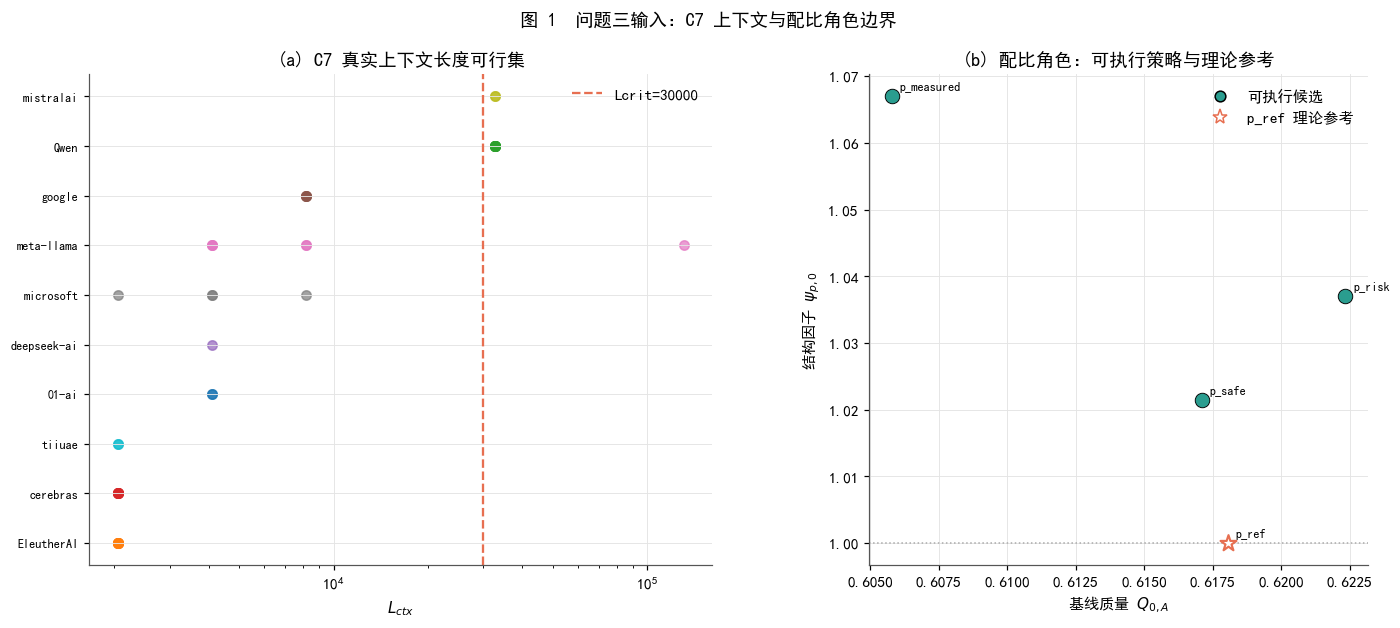

In [2]:
# ============ 1. 参数、配比角色与 C7 ============
TH = {k: float(Q2['classic_law'][k]) for k in ('E','A','alpha','B','beta')}

QUAL = Q2['quality']
KAPPA = float(QUAL['kappa'])
EXP_UNC = Q2.get('H1', {}).get('exponent_uncertainty', {})
KAPPA_CI = list(map(float, EXP_UNC.get('kappa_ci_B6_cluster', [KAPPA, KAPPA])))
if len(KAPPA_CI) != 2:
    KAPPA_CI = [KAPPA, KAPPA]

QBR = QUAL['Q_bridge']
CQ_NOMINAL = float(QBR.get('nominal_c_Q', 1.0))
CQ_SCENARIOS = list(map(float, QBR.get('sensitivity_c_Q', [0.75, 1.25])))
Q_REF_A = float(QBR['Qbar_A_ref'])
Q_RISK_A = float(QBR['Qbar_A_risk'])

MST = Q2['mixture_scale_transfer']
N0_MIX = float(MST['N0'])
GAMMA_IDENTIFIED = bool(MST['gamma_p_identified'])
GAMMA_SENSITIVITY_VALUES = sorted({float(v) for v in MST.get('gamma_sensitivity_values', [0.0])})
if not GAMMA_SENSITIVITY_VALUES or any(v < 0 or not np.isfinite(v) for v in GAMMA_SENSITIVITY_VALUES):
    raise ValueError('问题二 gamma_sensitivity_values 必须是有限非负值。')
GAMMA_P = float(MST['gamma_p_local']) if GAMMA_IDENTIFIED else 0.0
gamma_ci_raw = MST.get('gamma_p_matched_bootstrap_2p5_50_97p5')
GAMMA_CI = (list(map(float, gamma_ci_raw))
            if GAMMA_IDENTIFIED and gamma_ci_raw is not None else None)
if GAMMA_IDENTIFIED and (GAMMA_CI is None or len(GAMMA_CI) != 3):
    raise ValueError('已识别 gamma_p 时需要完整的 2.5/50/97.5 bootstrap 分位。')
MIX_FREEZE_N = 60e6
SCALE_SCENARIOS = []
for entry in MST.get('scale_scenarios', []):
    form, ga = str(entry['form']), float(entry['gamma'])
    if form not in {'local-power', 'frozen-after-60M', 'no-attenuation'} or ga < 0 or not np.isfinite(ga):
        raise ValueError(f'无效的配比尺度情景: {entry}')
    if form == 'no-attenuation' and ga != 0.0:
        raise ValueError('no-attenuation 情景的 gamma 必须为 0。')
    scenario = {'form':form, 'gamma':ga,
                'estimated':bool(entry.get('estimated', False)) and form=='local-power'}
    if not GAMMA_IDENTIFIED and scenario['estimated']:
        raise ValueError('未识别 gamma_p 时不能标记尺度情景为 estimated。')
    if (form, ga) not in {(x['form'], x['gamma']) for x in SCALE_SCENARIOS}:
        SCALE_SCENARIOS.append(scenario)
if not SCALE_SCENARIOS:
    raise ValueError('新版问题二接口必须提供 scale_scenarios。')
if GAMMA_IDENTIFIED:
    SCALE_FORM_NOMINAL = 'local-power'
else:
    if (0.0 not in GAMMA_SENSITIVITY_VALUES
            or not any(x['form']=='no-attenuation' and x['gamma']==0.0 for x in SCALE_SCENARIOS)):
        raise ValueError('未识别 gamma_p 时缺少无衰减零假设情景。')
    SCALE_FORM_NOMINAL = 'no-attenuation'

MB = Q2['mixture_bridge']
DOM17 = list(MB['domain_order'])
C0_MIX = float(MB['intercept'])
EPS_LOG = float(MB['epsilon'])
L_REF = float(MB['L_ref'])
A_LOG = np.array([float(MB['a_i'][d]) for d in DOM17])
P_REF = np.array([float(MB['p_ref'][d]) for d in DOM17])
P_RISK = np.array([float(MB['p_risk'][d]) for d in DOM17])
q1_risk = Q1_FINAL.get('risk_recipe_p')
if not isinstance(q1_risk, dict) or set(DOM17) - set(q1_risk):
    raise ValueError('新版问题一接口缺少完整的 risk_recipe_p。')
if not np.allclose(P_RISK, [float(q1_risk[d]) for d in DOM17], rtol=0, atol=1e-9):
    raise ValueError('新版问题一与问题二的风险配比不一致。')

G_PAR = Q2['cost_functions_appendixB']
B1_SUPPORT = pd.read_csv(F_ROOT / 'real_attachments' / 'B_scaling_laws' / 'pythia_training_log_existing.csv')
B1_N = B1_SUPPORT.N_params_B.to_numpy(float)*1e9
B1_D = B1_SUPPORT.D_tokens_B.to_numpy(float)*1e9
B1_C = 6.0*B1_N*B1_D
if not (np.isfinite(B1_N).all() and np.isfinite(B1_D).all() and (B1_N>0).all() and (B1_D>0).all()):
    raise ValueError('B1 规模支持范围含无效值。')
B1_LIMITS = {'N_min':float(B1_N.min()),'N_max':float(B1_N.max()),
             'D_min':float(B1_D.min()),'D_max':float(B1_D.max()),
             'C_min':float(B1_C.min()),'C_max':float(B1_C.max())}
def support_status(N,D):
    # 仅按 B1 的 N/D/6ND 边际范围分层；不声称四维联合验证。
    n,d = float(N),float(D)
    c = 6.0*n*d
    within = (B1_LIMITS['N_min'] <= n <= B1_LIMITS['N_max'] and
              B1_LIMITS['D_min'] <= d <= B1_LIMITS['D_max'] and
              B1_LIMITS['C_min'] <= c <= B1_LIMITS['C_max'])
    if within:
        return 'interpolation'
    moderate = (n >= B1_LIMITS['N_min']/10 and d >= B1_LIMITS['D_min']/10 and
                n <= 10*B1_LIMITS['N_max'] and d <= 10*B1_LIMITS['D_max'] and
                c <= 10*B1_LIMITS['C_max'])
    return 'moderate_extrapolation' if moderate else 'far_extrapolation'
ETA = 2e-4
L_CRIT = 6 / ETA
BUDGETS = [1e19, 1e22, 1e24]
BUD_LAB = {1e19:'低 1e19', 1e22:'中 1e22', 1e24:'高 1e24'}

def bridge_QA_to_QB(QA, c_q=None):
    c_q = CQ_NOMINAL if c_q is None else float(c_q)
    return np.clip(1.0 - c_q * (1.0 - np.asarray(QA, float)), 0.0, 1.0)

def psi_p0_vec(p):
    p = np.asarray(p, float)
    return float((C0_MIX + np.sum(A_LOG * np.log(p + EPS_LOG))) / L_REF)

def psi_p_at_N(N, psi_p0, gamma=None, scale_form=None):
    gamma = GAMMA_P if gamma is None else float(gamma)
    scale_form = SCALE_FORM_NOMINAL if scale_form is None else str(scale_form)
    n = np.asarray(N, float)
    if np.any(n <= 0):
        raise ValueError('N 必须为正。')
    if scale_form == 'no-attenuation':
        weight = np.ones_like(n, dtype=float)
    elif scale_form == 'frozen-after-60M':
        weight = (np.minimum(n, MIX_FREEZE_N)/N0_MIX)**(-gamma)
    elif scale_form == 'local-power':
        weight = (n/N0_MIX)**(-gamma)
    else:
        raise ValueError(f'未知尺度函数情景: {scale_form}')
    return 1.0 + weight * (float(psi_p0)-1.0)

G_COST = {
    '指数型': (
        lambda Q: G_PAR['exp']['gamma'] * np.exp(G_PAR['exp']['lambda'] * np.asarray(Q,float)),
        lambda Q: G_PAR['exp']['gamma'] * G_PAR['exp']['lambda'] * np.exp(G_PAR['exp']['lambda'] * np.asarray(Q,float)),
        lambda Q: G_PAR['exp']['gamma'] * G_PAR['exp']['lambda']**2 * np.exp(G_PAR['exp']['lambda'] * np.asarray(Q,float))),
    '幂函数型': (
        lambda Q: G_PAR['power']['gamma'] * np.asarray(Q,float)**G_PAR['power']['lambda'],
        lambda Q: G_PAR['power']['gamma'] * G_PAR['power']['lambda'] * np.asarray(Q,float)**(G_PAR['power']['lambda']-1),
        lambda Q: G_PAR['power']['gamma'] * G_PAR['power']['lambda'] * (G_PAR['power']['lambda']-1) * np.asarray(Q,float)**(G_PAR['power']['lambda']-2)),
    '对数渐进型': (
        lambda Q: G_PAR['log']['gamma'] * np.log(1 + G_PAR['log']['lambda'] * np.asarray(Q,float)),
        lambda Q: G_PAR['log']['gamma'] * G_PAR['log']['lambda'] / (1 + G_PAR['log']['lambda'] * np.asarray(Q,float)),
        lambda Q: -G_PAR['log']['gamma'] * G_PAR['log']['lambda']**2 / (1 + G_PAR['log']['lambda'] * np.asarray(Q,float))**2)
}
COSTS = list(G_COST)

# ---------- 递归寻找问题一正式导出的配比角色 ----------
def _vector_from_obj(v):
    if isinstance(v, dict) and all(d in v for d in DOM17):
        p = np.array([float(v[d]) for d in DOM17], float)
        if np.all(np.isfinite(p)) and p.sum() > 0 and np.all(p >= -1e-12):
            p = np.maximum(p, 0)
            return p / p.sum()
    return None

def recursive_find_key(obj, target_keys):
    hits = []
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k in target_keys:
                p = _vector_from_obj(v)
                if p is not None:
                    hits.append((k, p))
            hits.extend(recursive_find_key(v, target_keys))
    elif isinstance(obj, list):
        for v in obj:
            hits.extend(recursive_find_key(v, target_keys))
    return hits

# Q2 已固定采用新版 Q1 的领域质量向量；只用正式 Q1 接口交叉核验。
Q17_MAP = QUAL.get('mixture_domain_Q_res')
if not isinstance(Q17_MAP, dict) or set(DOM17) - set(Q17_MAP):
    raise ValueError('问题二接口缺少完整的 mixture_domain_Q_res。')
Q17 = np.array([float(Q17_MAP[d]) for d in DOM17], float)
if not np.all(np.isfinite(Q17)):
    raise ValueError('领域质量向量含非有限值。')
q1_map = Q1_FINAL.get('mixture_domain_Q')
if not isinstance(q1_map, dict) or set(DOM17) - set(q1_map):
    raise ValueError('新版问题一接口缺少完整的 mixture_domain_Q。')
if not np.allclose(Q17, [float(q1_map[d]) for d in DOM17], rtol=0, atol=1e-9):
    raise ValueError('新版问题一与问题二的领域质量向量不一致。')
if not np.isclose(Q_RISK_A, float(P_RISK @ Q17), rtol=0, atol=1e-8):
    raise ValueError('问题二风险配比的 Qbar 与领域质量向量不一致。')

def recursive_find_domain_q(obj):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k in {'mixture_domain_Q','domain_Q','Q_i'} and isinstance(v, dict) and all(d in v for d in DOM17):
                try:
                    return np.array([float(v[d]) for d in DOM17], float)
                except Exception:
                    pass
            out = recursive_find_domain_q(v)
            if out is not None:
                return out
    elif isinstance(obj, list):
        for v in obj:
            out = recursive_find_domain_q(v)
            if out is not None:
                return out
    return None


# 问题一正式导出的配比表比最终 JSON 更完整；仅接受明确标注的三种候选。
# 训练集实测最佳只表示 1M 训练配比有观测，不表示它已在目标尺度被实测。
recipe_path = Q1_TABLE / 'mpr_recipe_shares.csv'
evidence_path = Q1_TABLE / 'mpr_risk_recommendation.csv'
if not recipe_path.exists() or not evidence_path.exists():
    raise FileNotFoundError(
        '新版问题一需要同时导出 mpr_recipe_shares.csv 和 '
        'mpr_risk_recommendation.csv；缺失时不能声称配比参与联合选择。'
    )

recipe_table = pd.read_csv(recipe_path, index_col=0, encoding='utf-8-sig')
recipe_table.index = recipe_table.index.astype(str).str.strip()
required_recipe_columns = {
    'MPR 风险 p_risk': 'p_risk',
    '凸包保守 p_safe': 'p_safe',
    '训练集实测最佳': 'p_measured'
}
if (recipe_table.index.has_duplicates or set(recipe_table.index) != set(DOM17)
        or not set(required_recipe_columns).issubset(recipe_table.columns)):
    raise ValueError('问题一配比表的领域顺序或角色列与新版正式接口不一致。')
recipe_table = recipe_table.loc[DOM17]

def _validated_recipe(column):
    p = recipe_table[column].to_numpy(dtype=float)
    if (not np.isfinite(p).all() or (p < -1e-12).any()
            or not np.isclose(p.sum(), 1.0, rtol=0, atol=1e-7)):
        raise ValueError(f'问题一正式配比 {column} 不是合法的 17 域概率向量。')
    return p

p_from_q1 = {role: _validated_recipe(column)
             for column, role in required_recipe_columns.items()}
if not np.allclose(p_from_q1['p_risk'], P_RISK, rtol=0, atol=1e-9):
    raise ValueError('问题一配比表、问题一最终 JSON 与问题二中的 p_risk 不一致。')

recipe_evidence = pd.read_csv(evidence_path, encoding='utf-8-sig')
needed_evidence = {'recipe', 'has_new_training_observation'}
if not needed_evidence.issubset(recipe_evidence.columns):
    raise ValueError('问题一推荐证据表缺少配比身份或实测标记。')
if recipe_evidence['recipe'].duplicated().any():
    raise ValueError('问题一推荐证据表的配比身份重复。')
raw_observed = {
    str(row.recipe): str(row.has_new_training_observation).strip().lower()
    for row in recipe_evidence.itertuples(index=False)
}
if any(value not in {'true','false'} for value in raw_observed.values()):
    raise ValueError('问题一推荐证据表中的实测标记必须明确为 True 或 False。')
observed = {name:value == 'true' for name,value in raw_observed.items()}
if (observed.get('MPR 风险 p_risk') is not False
        or observed.get('凸包保守 p_safe') is not False
        or observed.get('训练集实测最佳') is not True):
    raise ValueError('问题一推荐证据表中的风险、支撑域或实测身份与正式定义不一致。')

role_specs = [
    ('p_risk', P_RISK, 'risk-controlled recommendation', 'Q1.mpr_recipe_shares.csv:MPR 风险 p_risk; Q2.mixture_bridge.p_risk'),
    ('p_safe', p_from_q1['p_safe'], 'support-constrained proxy recommendation', 'Q1.mpr_recipe_shares.csv:凸包保守 p_safe'),
    ('p_measured', p_from_q1['p_measured'], 'best observed 1M training recipe', 'Q1.mpr_recipe_shares.csv:训练集实测最佳')
]
rows = []
for role, p, evidence_role, source in role_specs:
    q0 = Q_RISK_A if role == 'p_risk' else float(p @ Q17)
    psi0 = psi_p0_vec(p)
    if not (np.isfinite(q0) and 0 <= q0 <= 1 and np.isfinite(psi0) and psi0 > 0):
        raise ValueError(f'{role} 的质量基线或配比因子无效。')
    rows.append({
        'p_name':role, 'role':evidence_role, 'executable':True,
        'Q0_A':q0, 'psi_p0':psi0, 'source':source
    })

EXEC = pd.DataFrame(rows)
EXEC_INFO = {
    r.p_name: {'Q0_A':float(r.Q0_A), 'psi_p0':float(r.psi_p0)}
    for _, r in EXEC.iterrows()
}
ALLOCATION_SCOPE = 'finite_executable_recipe_selection_with_conditional_N_D_Q'

REF_INFO = {
    'p_name':'p_ref',
    'role':'normalization reference / theoretical oracle',
    'executable':False,
    'Q0_A':Q_REF_A,
    'psi_p0':psi_p0_vec(P_REF),
    'source':'Q2.mixture_bridge.p_ref'
}

ROLE_TABLE = pd.concat([
    EXEC[['p_name','role','executable','Q0_A','psi_p0','source']],
    pd.DataFrame([REF_INFO])
], ignore_index=True)

# ---------- C7 ----------
C7 = pd.read_csv(C7_PATH)
C7['family'] = C7.model_name.astype(str).str.split('/').str[0]
C7['L_ctx'] = C7.max_position_embeddings.astype(int)
FEAS = sorted(C7.L_ctx.unique().tolist())
L_DEFAULT = int(np.median(C7.L_ctx))
L_ALL = sorted(set(FEAS + [int(L_CRIT)]))

par_tab = pd.DataFrame([
    ('E',TH['E'],'不可约损失'), ('A',TH['A'],'参数项系数'), ('alpha',TH['alpha'],'参数指数'),
    ('B',TH['B'],'数据项系数'), ('beta',TH['beta'],'数据指数'),
    ('kappa',KAPPA,f'质量效应；CI [{KAPPA_CI[0]:.4f},{KAPPA_CI[1]:.4f}]'),
    ('gamma_p',GAMMA_P,('matched 幅度参数；bootstrap '+str(GAMMA_CI) if GAMMA_IDENTIFIED
                          else '未识别；0 是无衰减结构零假设；敏感性值='+str(GAMMA_SENSITIVITY_VALUES))),
    ('c_Q',CQ_NOMINAL,f'质量坐标桥；敏感性 {CQ_SCENARIOS}'),
    ('eta',ETA,'注意力开销系数'), ('L_crit',L_CRIT,'注意力 = 基础训练')
], columns=['参数','取值','含义'])

print('参数台账：')
display(par_tab)
print('\n配比角色台账：')
display(ROLE_TABLE)
print('配置问题口径:', ALLOCATION_SCOPE, '；主尺度情景:', SCALE_FORM_NOMINAL, GAMMA_P)
print(f'\nC7: {len(C7)} 个模型；L_ctx 可行集={FEAS}；默认={L_DEFAULT}；L_crit={L_CRIT:.0f}')

ROLE_TABLE.to_csv(TAB/'mixture_role_ledger.csv', index=False, encoding='utf-8-sig')

# ---------- 图 1：沿用原有视觉语言，突出“可执行 vs 参考” ----------
fig = plt.figure(figsize=(15,5.8))
gs = gridspec.GridSpec(1,2,width_ratios=[1.25,1],wspace=0.28)

ax = fig.add_subplot(gs[0])
fams = C7.groupby('family').L_ctx.median().sort_values().index.tolist()
ypos = {f:i for i,f in enumerate(fams)}
for f,g in C7.groupby('family'):
    ax.scatter(g.L_ctx,[ypos[f]]*len(g),s=38,alpha=.72,label=None)
ax.axvline(L_CRIT,color=C_CORAL,ls='--',lw=1.5,label=f'Lcrit={L_CRIT:.0f}')
ax.set_xscale('log')
ax.set_yticks(range(len(fams))); ax.set_yticklabels(fams,fontsize=8)
ax.set_xlabel(r'$L_{ctx}$'); ax.set_title('(a) C7 真实上下文长度可行集')
ax.legend(frameon=False)

ax = fig.add_subplot(gs[1])
for _,r in ROLE_TABLE.iterrows():
    if r.executable:
        ax.scatter(r.Q0_A,r.psi_p0,s=90,marker='o',color=C_TEAL,edgecolor='black',linewidth=.6,zorder=3)
    else:
        ax.scatter(r.Q0_A,r.psi_p0,s=120,marker='*',facecolor='white',edgecolor=C_CORAL,linewidth=1.4,zorder=4)
    ax.annotate(r.p_name,(r.Q0_A,r.psi_p0),xytext=(5,4),textcoords='offset points',fontsize=8)
ax.axhline(1.0,color='#AAAAAA',ls=':',lw=1)
ax.set_xlabel(r'基线质量 $Q_{0,A}$')
ax.set_ylabel(r'结构因子 $\psi_{p,0}$')
ax.set_title('(b) 配比角色：可执行策略与理论参考')
ax.legend(handles=[
    Line2D([0],[0],marker='o',color='w',markerfacecolor=C_TEAL,markeredgecolor='black',label='可执行候选',markersize=7),
    Line2D([0],[0],marker='*',color='w',markerfacecolor='white',markeredgecolor=C_CORAL,label='p_ref 理论参考',markersize=10)
],frameon=False,loc='best')
fig.suptitle('图 1  问题三输入：C7 上下文与配比角色边界',fontsize=12)
savefig('fig01_inputs_and_roles.png'); plt.show()


## 2. 相对质量治理下的条件资源优化

### 2.1 避免双重计数

问题一针对混料观测中的领域均值质量，问题二针对真正改变数据质量时的损失响应；两个量的含义不同。对每个可执行配比用自身治理起点归一化：

\[
\widetilde\psi_Q(Q_A;\mathbf p)=
\frac{1+\kappa[1-T(Q_A;c_Q)]}
{1+\kappa[1-T(Q_{0,A}(\mathbf p);c_Q)]},
\qquad
\widetilde\psi_Q(Q_{0,A};\mathbf p)=1.
\]

名义模型中，只有 \(Q_A>Q_{0,A}\) 的追加治理通过此比值改善 Loss。代码的中性检查显示本次 \(p_{\rm risk}\) 在 \(Q_{0,A}=0.622345\) 处的相对因子恰为 1。这是模型构造的一致性检查，不是独立的干预因果验证。

### 2.2 目标、成本与比较对象

\[
\min_{\mathbf p\in\mathcal P_{\rm exec},\,N,D,Q_A}
L=E+(AN^{-\alpha}+BD^{-\beta})
\widetilde\psi_Q(Q_A;\mathbf p)\psi_p(\mathbf p,N)
\]

满足

\[
D\left[(6+\eta_{\rm attn}L_{ctx})N+g(Q_A)-g(Q_{0,A}(\mathbf p))\right]\le C,
\qquad Q_{0,A}(\mathbf p)\le Q_A\le1.
\]

本次 \(\mathcal P_{\rm exec}\) 只有一个元素，故上述外层配比选择在数值上退化为固定 \(p_{\rm risk}\) 的连续配置。\(p_{\rm ref}\) 用同一模型另行计算 \(L_{\rm ref}^{\star}\)。保存结果中 \(L_{\rm exec}^{\star}-L_{\rm ref}^{\star}>0\)，它只是**模型内、两种配比条件下的预测差值**；本次没有证明 \(L_{\rm ref}^{\star}\) 对所有可执行策略或真实训练结果构成普适下界，也不能将差值当作已实测的性能损失。

### 2.3 数值求解与体制定义

由于最优解通常用满预算，代码以

\[
H=(6+\eta_{\rm attn}L_{ctx})N+g(Q_A)-g(Q_{0,A}),\qquad D=C/H
\]

消去 \(D\)，在给定 \(Q_A\) 时对有限 \(\log N\) 网格扫描导数变号区间并求根，同时比较参数边界；冻结衰减情景还比较 60M 处的折点。质量方向枚举两端点及扫描发现的内部 \(\rho_Q=1\) 候选，再比较目标值。该程序给出数值候选与残差证书，**不保证检出未造成符号变号的所有驻点**。

\[
\rho_Q=
\frac{-\widetilde\psi_Q'(Q_A)\,R\,H}
{\widetilde\psi_Q(Q_A)\,\beta BD^{-\beta}g'(Q_A)},
\qquad R=AN^{-\alpha}+BD^{-\beta}.
\]

R0 表示 \(Q_A=Q_{0,A}\)；R1 表示 \(Q_{0,A}<Q_A<1\)；R2 表示 \(Q_A=1\)。相应的 \(\rho_Q\le1,=1,\ge1\) 是局部最优的边界或内部条件；多分支时仍需比较 Loss。转移表中的 `root_of_declared_condition` 表示所列 KKT 条件或分支等值条件的数值根，`numerical_state_boundary` 仅表示优化状态通过二分发生切换。


In [3]:
# ============ 2. 相对质量因子 + KKT 主动集求解器 ============
def R_fun(N,D,th=None):
    th = TH if th is None else th
    return th['A']*np.asarray(N,float)**(-th['alpha']) + th['B']*np.asarray(D,float)**(-th['beta'])

def psi_Q_abs(QA,kappa=None,c_q=None):
    kappa = KAPPA if kappa is None else float(kappa)
    qb = bridge_QA_to_QB(QA, CQ_NOMINAL if c_q is None else c_q)
    return 1.0 + kappa*(1.0-qb)

def dpsi_Q_abs_dQA(QA,kappa=None,c_q=None):
    kappa = KAPPA if kappa is None else float(kappa)
    c_q = CQ_NOMINAL if c_q is None else float(c_q)
    raw = 1.0 - c_q*(1.0-float(QA))
    return -kappa*c_q if raw > 0.0 else 0.0

def psi_Q_rel(QA,Q0_A,kappa=None,c_q=None):
    den = float(psi_Q_abs(Q0_A,kappa,c_q))
    return np.asarray(psi_Q_abs(QA,kappa,c_q),float) / den

def dpsi_Q_rel_dQA(QA,Q0_A,kappa=None,c_q=None):
    den = float(psi_Q_abs(Q0_A,kappa,c_q))
    return float(dpsi_Q_abs_dQA(QA,kappa,c_q)) / den

def L_gen(N,D,QA,Q0_A,th=None,kappa=None,psi_p0=1.0,gamma=None,c_q=None,scale_form=None):
    th = TH if th is None else th
    pp = psi_p_at_N(N,psi_p0,GAMMA_P if gamma is None else gamma,scale_form)
    qrel = psi_Q_rel(QA,Q0_A,kappa,c_q)
    return th['E'] + R_fun(N,D,th)*qrel*pp

# 逻辑证书：任意配比在 Q=Q0 时质量因子必须严格等于 1
QUALITY_NEUTRALITY = []
for p_name,info in EXEC_INFO.items():
    qf = float(psi_Q_rel(info['Q0_A'],info['Q0_A']))
    QUALITY_NEUTRALITY.append({'p_name':p_name,'Q0_A':info['Q0_A'],'psiQ_rel_at_Q0':qf})
QUALITY_NEUTRALITY = pd.DataFrame(QUALITY_NEUTRALITY)
assert np.allclose(QUALITY_NEUTRALITY.psiQ_rel_at_Q0,1.0,atol=1e-12)

def _rho_Q(N,D,QA,cost,Q0_A,th=None,kappa=None,psi_p0=1.0,
           gamma=None,c_q=None,L=None,eta=None):
    th = TH if th is None else th
    eta = ETA if eta is None else float(eta)
    g,gp,_ = G_COST[cost]
    cN = 6 + eta*float(L)
    H = cN*float(N) + max(float(g(QA)-g(Q0_A)),0.0)

    qf = float(psi_Q_rel(QA,Q0_A,kappa,c_q))
    dq = float(dpsi_Q_rel_dQA(QA,Q0_A,kappa,c_q))
    benefit = max(-dq,0.0)*float(R_fun(N,D,th))*H
    marginal_cost = qf*th['beta']*th['B']*float(D)**(-th['beta'])*float(gp(QA))
    if marginal_cost <= 0:
        return np.inf if benefit > 0 else 0.0
    return float(benefit/marginal_cost)

def _fixedQ_kkt(C,L,cost,Qfix,Q0_A,th=None,kappa=None,psi_p0=1.0,
                eta=None,n_bounds=(1e5,1e14),gamma=None,c_q=None,scale_form=None):
    th = TH if th is None else th
    eta = ETA if eta is None else float(eta)
    gamma = GAMMA_P if gamma is None else float(gamma)
    c_q = CQ_NOMINAL if c_q is None else float(c_q)
    scale_form = SCALE_FORM_NOMINAL if scale_form is None else str(scale_form)

    g,_,_ = G_COST[cost]
    cN = 6 + eta*L
    Qfix,Q0_A = float(Qfix),float(Q0_A)
    dgq = max(float(g(Qfix)-g(Q0_A)),0.0)
    qrel = float(psi_Q_rel(Qfix,Q0_A,kappa,c_q))
    lo,hi = map(np.log,n_bounds)

    def dlogN(lnN):
        n = float(np.exp(lnN))
        H = cN*n + dgq
        d = C/H
        R = float(R_fun(n,d,th))
        pp = float(psi_p_at_N(n,psi_p0,gamma,scale_form))
        active_power = (scale_form == 'local-power' or
                        (scale_form == 'frozen-after-60M' and n < MIX_FREEZE_N))
        dpp = -gamma*(pp-1.0)/n if active_power else 0.0
        dR = (
            -th['alpha']*th['A']*n**(-th['alpha']-1)
            + th['beta']*th['B']*d**(-th['beta'])*cN/H
        )
        return float(qrel*n*(dpp*R + pp*dR))

    grid = np.linspace(lo,hi,121)
    vals = np.array([dlogN(z) for z in grid])
    roots = []
    for i in range(len(grid)-1):
        a,b,fa,fb = grid[i],grid[i+1],vals[i],vals[i+1]
        if not (np.isfinite(fa) and np.isfinite(fb)):
            continue
        if abs(fa) < 1e-11:
            roots.append(float(a))
        if fa*fb < 0:
            try:
                roots.append(float(brentq(dlogN,a,b,xtol=1e-11,rtol=1e-11,maxiter=150)))
            except ValueError:
                pass

    cand_ln = [lo,hi]
    if scale_form == 'frozen-after-60M' and n_bounds[0] < MIX_FREEZE_N < n_bounds[1]:
        cand_ln.append(float(np.log(MIX_FREEZE_N)))
    for z in roots:
        if not any(abs(z-t)<1e-8 for t in cand_ln):
            cand_ln.append(z)

    def state(z):
        n = float(np.exp(z))
        H = cN*n + dgq
        d = C/H
        return n,d,float(L_gen(n,d,Qfix,Q0_A,th,kappa,psi_p0,gamma,c_q,scale_form))

    states = [(*state(z),z) for z in cand_ln]
    n,d,loss,lnN = min(states,key=lambda t:t[2])

    scale = max(abs(loss-th['E']),1e-12)
    at_kink = scale_form == 'frozen-after-60M' and abs(n-MIX_FREEZE_N)/MIX_FREEZE_N < 1e-9
    nres = (abs(dlogN(lnN))/scale
            if lo+1e-7 < lnN < hi-1e-7 and not at_kink else np.nan)
    rho = _rho_Q(n,d,Qfix,cost,Q0_A,th,kappa,psi_p0,gamma,c_q,L,eta)

    return {
        'N':n,'D':d,'Q':Qfix,'loss':loss,'rho':rho,
        'N_kkt_logresid':float(nres) if np.isfinite(nres) else np.nan,
        'N_stationarity_status':'nonsmooth_kink' if at_kink else ('interior' if np.isfinite(nres) else 'bound'),
        'dg':dgq,'psi_p_N':float(psi_p_at_N(n,psi_p0,gamma,scale_form))
    }

def _all_Q_roots(C,L,cost,Q0_A,th=None,kappa=None,psi_p0=1.0,
                 eta=None,nscan=101,gamma=None,c_q=None,scale_form=None):
    if 1-Q0_A < 1e-10:
        return []
    qs = np.linspace(Q0_A,1.0,nscan)
    cache = {}

    def f(q):
        key = round(float(q),14)
        if key not in cache:
            cache[key] = (
                _fixedQ_kkt(C,L,cost,float(q),Q0_A,th,kappa,psi_p0,eta,
                            gamma=gamma,c_q=c_q,scale_form=scale_form)['rho'] - 1.0
            )
        return cache[key]

    vals = np.array([f(q) for q in qs])
    roots = []
    for i in range(len(qs)-1):
        a,b,fa,fb = qs[i],qs[i+1],vals[i],vals[i+1]
        if not (np.isfinite(fa) and np.isfinite(fb)):
            continue
        if abs(fa) < 1e-9 and Q0_A+1e-8 < a < 1-1e-8:
            roots.append(float(a))
        if fa*fb < 0:
            try:
                r = float(brentq(f,a,b,xtol=1e-10,rtol=1e-10,maxiter=120))
                if Q0_A+1e-8 < r < 1-1e-8:
                    roots.append(r)
            except ValueError:
                pass

    out = []
    for q in sorted(roots):
        if not out or abs(q-out[-1]) > 1e-7:
            out.append(q)
    return out

def enumerate_active_sets(C,L,cost,Q0_A,th=None,kappa=None,psi_p0=1.0,
                          eta=None,nscan=101,gamma=None,c_q=None,scale_form=None):
    roots = _all_Q_roots(C,L,cost,Q0_A,th,kappa,psi_p0,eta,nscan,gamma,c_q,scale_form)
    qlist = [float(Q0_A)] + roots + ([1.0] if abs(1-Q0_A)>1e-12 else [])
    cand = []

    for q in qlist:
        s = _fixedQ_kkt(C,L,cost,q,Q0_A,th,kappa,psi_p0,eta,gamma=gamma,c_q=c_q,scale_form=scale_form)
        regime = 'R0' if abs(q-Q0_A)<1e-7 else ('R2' if abs(q-1)<1e-7 else 'R1')
        if regime == 'R0':
            qv = max(s['rho']-1,0.0)
        elif regime == 'R2':
            qv = max(1-s['rho'],0.0)
        else:
            qv = abs(s['rho']-1)
        s.update({'regime':regime,'Q_kkt_violation':float(qv)})
        cand.append(s)
    return cand

def solve_alloc_certified(C,L,cost,Q0_A,th=None,kappa=None,psi_p0=1.0,
                          eta=None,nscan=101,return_candidates=False,
                          gamma=None,c_q=None,scale_form=None):
    eta = ETA if eta is None else float(eta)
    gamma = GAMMA_P if gamma is None else float(gamma)
    c_q = CQ_NOMINAL if c_q is None else float(c_q)
    scale_form = SCALE_FORM_NOMINAL if scale_form is None else str(scale_form)
    g = G_COST[cost][0]

    cand = enumerate_active_sets(C,L,cost,Q0_A,th,kappa,psi_p0,eta,nscan,gamma,c_q,scale_form)
    best = min(cand,key=lambda z:z['loss']).copy()

    n,d,q = best['N'],best['D'],best['Q']
    dgq = max(float(g(q)-g(Q0_A)),0.0)
    used = (6+eta*L)*n*d + d*dgq

    best.update({
        'C':C,'L_ctx':L,'cost':cost,'Q0_A':float(Q0_A),'psi_p0':float(psi_p0),
        'Q_B':float(bridge_QA_to_QB(q,c_q)),'gamma_p':gamma,'c_Q':c_q,
        'gamma_p_identified':GAMMA_IDENTIFIED,'scale_form':scale_form,
        'support_status':support_status(n,d),'extrapolation_flag':support_status(n,d)!='interpolation',
        'D_over_N':d/n,'s_train':6*n*d/C,'s_attn':eta*L*n*d/C,'s_Q':d*dgq/C,
        'C_train':6*n*d,'C_attn':eta*L*n*d,'C_Q':d*dgq,
        'budget_resid':abs(used/C-1.0),'method':'active-set-KKT-relativeQ'
    })
    nr = best.get('N_kkt_logresid',np.nan)
    best['certificate'] = max(
        best['budget_resid'],
        0.0 if not np.isfinite(nr) else nr,
        best['Q_kkt_violation']
    )
    if return_candidates:
        best['candidates'] = cand
    return best

def solve_executable(C,L,cost,th=None,kappa=None,eta=None,nscan=101,
                     return_all=False,gamma=None,c_q=None,scale_form=None):
    """只在问题一明确支持的可执行配比集合中寻优。"""
    results = []
    for p_name,info in EXEC_INFO.items():
        s = solve_alloc_certified(
            C,L,cost,info['Q0_A'],th,kappa,info['psi_p0'],eta,
            nscan=nscan,gamma=gamma,c_q=c_q,scale_form=scale_form
        )
        s['p_name'] = p_name
        s['decision_role'] = 'executable'
        results.append(s)

    best = min(results,key=lambda z:z['loss']).copy()
    if return_all:
        best['p_candidates'] = results
    return best

def solve_reference_oracle(C,L,cost,th=None,kappa=None,eta=None,nscan=101,
                           gamma=None,c_q=None,scale_form=None):
    """p_ref 只作理论参考，不进入可执行 argmin。"""
    s = solve_alloc_certified(
        C,L,cost,REF_INFO['Q0_A'],th,kappa,REF_INFO['psi_p0'],eta,
        nscan=nscan,gamma=gamma,c_q=c_q,scale_form=scale_form
    )
    s['p_name'] = 'p_ref'
    s['decision_role'] = 'theoretical_reference'
    return s

# ---------- 三个逻辑一致性断言 ----------
assert 'p_ref' not in EXEC_INFO
assert REF_INFO['executable'] is False
assert np.allclose(QUALITY_NEUTRALITY.psiQ_rel_at_Q0,1.0,atol=1e-12)

print('相对质量因子中性检查：')
display(QUALITY_NEUTRALITY)

CHECK = []
for C in BUDGETS:
    s = solve_executable(C,L_DEFAULT,'指数型')
    o = solve_reference_oracle(C,L_DEFAULT,'指数型')
    CHECK.append({
        'C':C,'exec_p':s['p_name'],'regime':s['regime'],
        'N(B)':s['N']/1e9,'D(B)':s['D']/1e9,'Q_A':s['Q'],'Loss_exec':s['loss'],
        'Loss_ref':o['loss'],'evidence_gap':s['loss']-o['loss'],
        'certificate':s['certificate']
    })
CHECK = pd.DataFrame(CHECK)
print('\n可执行策略与理论参考（p_ref 不参与实际决策）：')
display(CHECK)


相对质量因子中性检查：


,p_name,Q0_A,psiQ_rel_at_Q0
0,p_risk,0.622345,1
1,p_safe,0.617122,1
2,p_measured,0.605803,1



可执行策略与理论参考（p_ref 不参与实际决策）：


,C,exec_p,regime,N(B),D(B),Q_A,Loss_exec,Loss_ref,evidence_gap,certificate
0,1e+19,p_safe,R1,0.303426,3.5957,0.786053,3.02336,2.99567,0.0276945,1.44329e-15
1,1e+22,p_safe,R2,5.42781,246.051,1,2.09355,2.08522,0.00833078,4.15066e-16
2,1e+24,p_safe,R2,39.5583,3657.85,1,1.88628,1.88223,0.00405223,8.12411e-16


## 3. 三档预算的已保存结果

默认 \(L_{ctx}=4096\)，预算为 \(10^{19},10^{22},10^{24}\)，三类质量成本分别求解。各行可执行配比均为 \(p_{\rm risk}\)，主尺度形式均为**无衰减**；以下 Loss 是拟合模型的预测值，不是新增训练实验的实测值。

| 成本函数 | \(C=10^{19}\)：体制 / Loss | \(C=10^{22}\)：体制 / Loss | \(C=10^{24}\)：体制 / Loss |
|---|---:|---:|---:|
| 指数型 | R1 / 3.04537 | R2 / 2.10053 | R2 / 1.88969 |
| 幂函数型 | R0 / 3.06036 | R2 / 2.10154 | R2 / 1.88976 |
| 对数渐进型 | R2 / 2.93470 | R2 / 2.09580 | R2 / 1.88937 |

指数型成本下，\(Q_A^\star\) 依次为 0.783196、1、1；\(N^\star\) 分别约为 0.300、5.426、39.556 十亿参数，\(D^\star\) 分别约为 3.666、246.204、3658.22 十亿 token。指数型的质量治理预算份额 \(s_Q\) 由 0.2493 降至 0.0890、0.0132；这说明在这些已算预算点上，R2 的固定质量投入随总预算增大而占比下降，不能据此断言所有预算或所有成本函数上的边际分配规律。

\(p_{\rm ref}\) 单独计算为比较值。指数型三档预算中 \(L_{\rm exec}^\star-L_{\rm ref}^\star\) 依次约为 0.04970、0.01531、0.00746；它不进入推荐策略。三类成本在 \(10^{24}\) 的结果均被标为 `far_extrapolation`，因此高预算数值只能作模型情景外推。\(10^{19}\) 与 \(10^{22}\) 的 `interpolation` 也仅检查了 B1 的 \(N,D,6ND\) **边际范围**，不代表 \((N,D,Q_A,\mathbf p)\) 联合区域已经验证。


,成本函数,C,可执行配比,N_B,D_B,D_over_N,Q_A,Q_B,Loss,regime,s_train,s_attn,s_Q,reference_loss,evidence_gap,evidence_gap_%,certificate,support_status,extrapolation_flag,scale_form,gamma_p_identified
0,指数型,1e+19,p_safe,0.303426,3.5957,11.8503,0.786053,0.786053,3.02336,R1,0.654617,0.089377,0.256006,2.99567,0.0276945,0.924484,1.44329e-15,interpolation,False,no-attenuation,False
1,指数型,1e+22,p_safe,5.42781,246.051,45.3314,1,1,2.09355,R2,0.80131,0.109406,0.0892846,2.08522,0.00833078,0.399516,4.15066e-16,interpolation,False,no-attenuation,False
2,指数型,1e+24,p_safe,39.5583,3657.85,92.4675,1,1,1.88628,R2,0.86819,0.118537,0.0132733,1.88223,0.00405223,0.215289,8.12411e-16,far_extrapolation,True,no-attenuation,False
3,幂函数型,1e+19,p_safe,0.215207,6.81412,31.6631,0.617122,0.617122,3.03977,R0,0.879869,0.120131,0,3.01143,0.028333,0.940847,1.19207e-14,interpolation,False,no-attenuation,False
4,幂函数型,1e+22,p_safe,5.51739,238.669,43.2577,1,1,2.09457,R2,0.790099,0.107875,0.102026,2.08621,0.00835491,0.400483,3.17556e-15,interpolation,False,no-attenuation,False
5,幂函数型,1e+24,p_safe,39.665,3639.56,91.7577,1,1,1.88636,R2,0.866179,0.118262,0.0155584,1.8823,0.00405394,0.215371,1.00903e-15,far_extrapolation,True,no-attenuation,False
6,对数渐进型,1e+19,p_safe,0.317024,3.31401,10.4535,1,1,2.91453,R2,0.630373,0.086067,0.28356,2.88908,0.0254458,0.880755,4.3197e-13,interpolation,False,no-attenuation,False
7,对数渐进型,1e+22,p_safe,5.01092,285.501,56.9757,1,1,2.08891,R2,0.858375,0.117197,0.0244286,2.08067,0.00823601,0.395834,9.86729e-16,interpolation,False,no-attenuation,False
8,对数渐进型,1e+24,p_safe,39.0942,3739.06,95.6423,1,1,1.88597,R2,0.877054,0.119747,0.00319928,1.88193,0.00404588,0.214986,5.94372e-16,far_extrapolation,True,no-attenuation,False



自动结果摘要：
指数型: 配比=['p_safe', 'p_safe', 'p_safe']; 体制=R1 → R2 → R2; Loss=3.0234, 2.0935, 1.8863
幂函数型: 配比=['p_safe', 'p_safe', 'p_safe']; 体制=R0 → R2 → R2; Loss=3.0398, 2.0946, 1.8864
对数渐进型: 配比=['p_safe', 'p_safe', 'p_safe']; 体制=R2 → R2 → R2; Loss=2.9145, 2.0889, 1.8860


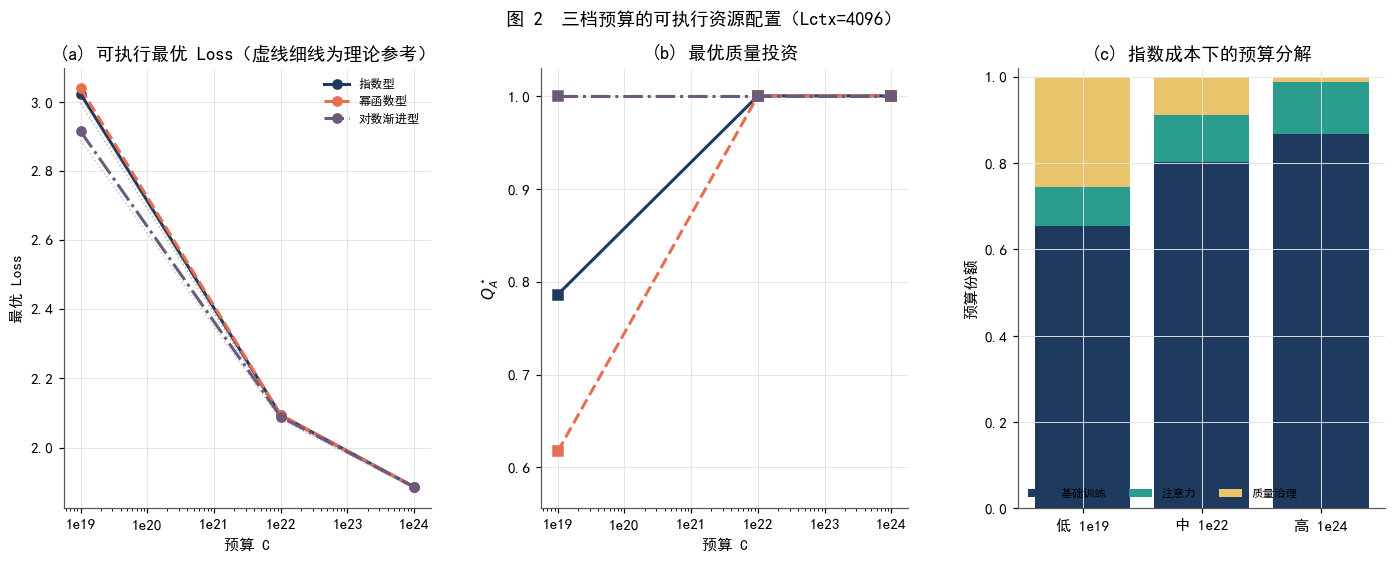

In [4]:
# ============ 3. 三档预算 × 三类成本：可执行策略 + 理论参考 ============
rows = []
for cost in COSTS:
    for C in BUDGETS:
        s = solve_executable(C,L_DEFAULT,cost)
        o = solve_reference_oracle(C,L_DEFAULT,cost)
        rows.append({
            '成本函数':cost,'C':C,
            '可执行配比':s['p_name'],
            'N_B':s['N']/1e9,'D_B':s['D']/1e9,'D_over_N':s['D_over_N'],
            'Q_A':s['Q'],'Q_B':s['Q_B'],'Loss':s['loss'],'regime':s['regime'],
            's_train':s['s_train'],'s_attn':s['s_attn'],'s_Q':s['s_Q'],
            'reference_loss':o['loss'],
            'evidence_gap':s['loss']-o['loss'],
            'evidence_gap_%':100*(s['loss']-o['loss'])/o['loss'],
            'certificate':s['certificate'],
            'support_status':s['support_status'],'extrapolation_flag':s['extrapolation_flag'],
            'scale_form':s['scale_form'],'gamma_p_identified':GAMMA_IDENTIFIED
        })

RES3 = pd.DataFrame(rows)
RES3.to_csv(TAB/'optimal_executable_allocation_three_budgets.csv',index=False,encoding='utf-8-sig')
display(RES3)

print('\n自动结果摘要：')
for cost in COSTS:
    sub = RES3[RES3['成本函数']==cost].sort_values('C')
    print(
        f"{cost}: 配比={list(sub['可执行配比'])}; "
        f"体制={' → '.join(sub.regime)}; "
        f"Loss={', '.join(f'{x:.4f}' for x in sub.Loss)}"
    )

# 图 2：沿用原版多面板风格
fig = plt.figure(figsize=(15.5,5.2))
gs = gridspec.GridSpec(1,3,wspace=.30)

ax = fig.add_subplot(gs[0])
for cost in COSTS:
    sub = RES3[RES3['成本函数']==cost].sort_values('C')
    ax.plot(sub.C,sub.Loss,marker='o',lw=2.0,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
    ax.plot(sub.C,sub.reference_loss,lw=1.0,color=COL_COST[cost],alpha=.35,ls=':')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('最优 Loss')
ax.set_title('(a) 可执行最优 Loss（虚线细线为理论参考）')
ax.legend(frameon=False,fontsize=8)

ax = fig.add_subplot(gs[1])
for cost in COSTS:
    sub = RES3[RES3['成本函数']==cost].sort_values('C')
    ax.plot(sub.C,sub.Q_A,marker='s',lw=2.0,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel(r'$Q_A^\star$')
ax.set_ylim(max(0,EXEC.Q0_A.min()-.05),1.03)
ax.set_title('(b) 最优质量投资')

ax = fig.add_subplot(gs[2])
sub = RES3[RES3['成本函数']=='指数型'].sort_values('C')
x = np.arange(len(sub))
ax.bar(x,sub.s_train,label='基础训练',color=C_NAVY)
ax.bar(x,sub.s_attn,bottom=sub.s_train,label='注意力',color=C_TEAL)
ax.bar(x,sub.s_Q,bottom=sub.s_train+sub.s_attn,label='质量治理',color=C_GOLD)
ax.set_xticks(x); ax.set_xticklabels([BUD_LAB[c] for c in sub.C])
ax.set_ylim(0,1.02); ax.set_ylabel('预算份额')
ax.set_title('(c) 指数成本下的预算分解')
ax.legend(frameon=False,ncol=3,fontsize=7.5)

fig.suptitle(f'图 2  三档预算的可执行资源配置（Lctx={L_DEFAULT}）',fontsize=12)
savefig('fig02_three_budget_executable.png'); plt.show()


## 4. 连续预算扫描与结构转移的证据等级

代码在 \(C\in[10^{16},10^{27}]\) 上扫描并自适应加密状态变化区间。因为本次只有 \(p_{\rm risk}\) 可执行，状态签名实际是 \((p_{\rm risk},\mathrm{R0/R1/R2})\)，不存在已验证的可执行配比切换。\(p_{\rm ref}\) 只计算同预算下的比较曲线，不参与状态判定。

默认 \(L_{ctx}=4096\) 的转移表给出三种不同证据：

| 成本函数 | 转移 | 预算 \(C\) | 定位机制 |
|---|---|---:|---|
| 指数型 | R0→R1 | \(4.12751\times10^{18}\) | \(\rho_Q(Q_{0,A})=1\) 的数值根 |
| 指数型 | R1→R2 | \(7.08645\times10^{19}\) | 状态二分；KKT 边界未证实 |
| 幂函数型 | R0→R1 | \(1.75018\times10^{19}\) | \(\rho_Q(Q_{0,A})=1\) 的数值根 |
| 幂函数型 | R1→R2 | \(2.01117\times10^{19}\) | 状态二分；KKT 边界未证实 |
| 对数渐进型 | R0→R2 | \(5.29307\times10^{17}\) | 两个端点分支等值的数值根 |

两处 R1→R2 数值应理解为**已扫描状态的切换位置估计**，不能写成连续 KKT 边界的精确值；是否存在很窄的中间分支也受扫描分辨率约束。对数渐进型的直接跳变是模型内端点分支比较结果。图中的 \(L_{\rm exec}^{\star}-L_{\rm ref}^{\star}\) 仍只是参考差值，不能解释为因果“证据代价”或可实现的额外收益。


continuation 完成，用时 204.68s


,成本函数,L_ctx,C_transition,from_p,from_regime,to_p,to_regime,定位机制,boundary_status,C_bracket_low,C_bracket_high,scale_form,gamma_p_identified,rho_Q0_left,rho_Q0_right,rho_Q1_left,rho_Q1_right,branch_gap_left,branch_gap_right,branch_value_gap,branch_Q_jump
0,指数型,4096,3.86826e+18,p_safe,R0,p_safe,R1,state bisection; mechanism unverified,numerical_state_boundary,3.86826e+18,3.88398e+18,no-attenuation,False,1,1.00183,NaN,NaN,NaN,NaN,NaN,NaN
1,指数型,4096,7.0363e+19,p_safe,R1,p_safe,R2,state bisection; mechanism unverified,numerical_state_boundary,7.01055e+19,7.03631e+19,no-attenuation,False,NaN,NaN,0.99913,1,NaN,NaN,NaN,NaN
2,幂函数型,4096,1.66239e+19,p_safe,R0,p_safe,R1,state bisection; mechanism unverified,numerical_state_boundary,1.66239e+19,1.66968e+19,no-attenuation,False,1,1.00198,NaN,NaN,NaN,NaN,NaN,NaN
3,幂函数型,4096,1.96784e+19,p_safe,R1,p_safe,R2,R1/R2 branch value crossing; global envelope c...,root_of_declared_condition,1.96585e+19,1.97057e+19,no-attenuation,False,NaN,NaN,1.00798,1.00844,-1.86585e-05,2.51416e-05,2.73781e-12,0.158501
4,对数渐进型,4096,5.24973e+17,p_safe,R0,p_safe,R2,R0/R2 branch value crossing; global envelope c...,root_of_declared_condition,5.23299e+17,5.53737e+17,no-attenuation,False,NaN,NaN,NaN,NaN,NaN,NaN,2.68708e-10,0.382878


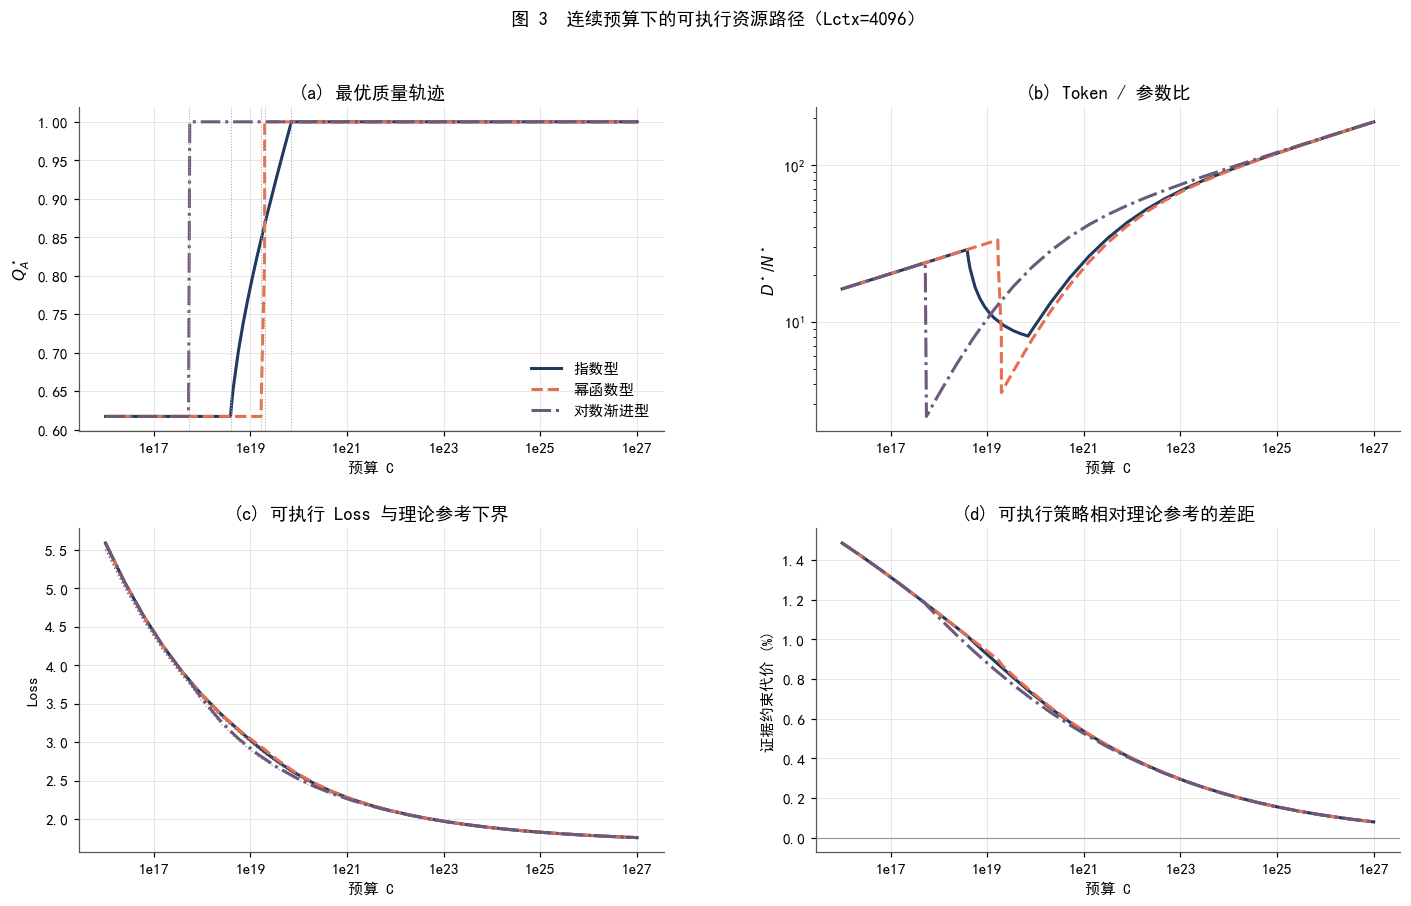

In [5]:
# ============ 4. continuation + 精确转移 ============
def _rho_boundary_roots_for_p(L,cost,p_name,qside='Q0',th=None,kappa=None,eta=None,lo=15,hi=28,
                              gamma=None,c_q=None,scale_form=None):
    info = EXEC_INFO[p_name]
    qfix = info['Q0_A'] if qside == 'Q0' else 1.0

    def f(lc):
        s = _fixedQ_kkt(10**lc,L,cost,qfix,info['Q0_A'],th,kappa,info['psi_p0'],eta,
                        gamma=gamma,c_q=c_q,scale_form=scale_form)
        return np.log(max(s['rho'],1e-300))

    grid = np.linspace(lo,hi,55)
    vals = np.array([f(x) for x in grid])
    roots = []
    for i in range(len(grid)-1):
        if np.isfinite(vals[i]) and np.isfinite(vals[i+1]) and vals[i]*vals[i+1] < 0:
            roots.append(10**brentq(f,grid[i],grid[i+1],xtol=1e-8,rtol=1e-9))
    return roots

def _state_sig(s):
    return (s['p_name'],s['regime'])

def adaptive_budget_scan(L,cost,th=None,kappa=None,eta=None,
                         log_lo=16,log_hi=27,base_n=29,max_depth=4,
                         gamma=None,c_q=None,scale_form=None):
    logs = set(np.linspace(log_lo,log_hi,base_n).tolist())

    for p in EXEC_INFO:
        for side in ('Q0','Q1'):
            roots = _rho_boundary_roots_for_p(
                L,cost,p,'Q0' if side=='Q0' else 'Q1',
                th,kappa,eta,log_lo-1,log_hi+1,gamma,c_q,scale_form
            )
            for C0_ in roots:
                lc = np.log10(C0_)
                if log_lo < lc < log_hi:
                    for d in (-.03,0,.03):
                        logs.add(float(np.clip(lc+d,log_lo,log_hi)))

    cache = {}
    def get(lc):
        key = round(float(lc),12)
        if key not in cache:
            cache[key] = solve_executable(
                10**lc,L,cost,th,kappa,eta,nscan=35,gamma=gamma,c_q=c_q,scale_form=scale_form
            )
        return cache[key]

    for _ in range(max_depth):
        ls = sorted(logs)
        add = []
        for a,b in zip(ls[:-1],ls[1:]):
            sa,sb = get(a),get(b)
            need = (
                _state_sig(sa) != _state_sig(sb)
                or abs(sa['Q']-sb['Q']) > .055
                or ((b-a)>.35 and (sa['regime']=='R1' or sb['regime']=='R1'))
            )
            if need and b-a > 2e-3:
                add.append((a+b)/2)
        if not add:
            break
        logs.update(add)

    rows = []
    for lc in sorted(logs):
        s = get(lc)
        o = solve_reference_oracle(10**lc,L,cost,th,kappa,eta,nscan=35,gamma=gamma,c_q=c_q,scale_form=scale_form)
        rows.append({
            'log10C':lc,'C':10**lc,
            **{k:s[k] for k in ('N','D','Q','Q_B','loss','regime','p_name','s_train','s_attn','s_Q','certificate',
                              'support_status','extrapolation_flag','scale_form')},
            'reference_loss':o['loss'],
            'evidence_gap':s['loss']-o['loss']
        })

    df = pd.DataFrame(rows).sort_values('C').reset_index(drop=True)
    lnC = np.log(df.C.values)
    df['D_over_N'] = df.D/df.N
    df['eps_N'] = np.gradient(np.log(df.N.values),lnC)
    df['eps_D'] = np.gradient(np.log(df.D.values),lnC)
    df['eps_Q'] = np.gradient(df.Q.values,lnC)
    return df

def _regime_candidate(C,L,cost,p_name,regime,th=None,kappa=None,eta=None,
                      gamma=None,c_q=None,scale_form=None,nscan=81):
    """Best numerically found stationary candidate on one executable recipe/regime branch."""
    info = EXEC_INFO[p_name]
    candidates = enumerate_active_sets(
        C,L,cost,info['Q0_A'],th,kappa,info['psi_p0'],eta,
        nscan=nscan,gamma=gamma,c_q=c_q,scale_form=scale_form
    )
    valid = [s for s in candidates if
             s['regime'] == regime and np.isfinite(s['loss'])
             and s['Q_kkt_violation'] <= 1e-6]
    if regime == 'R1':
        # 驻点也可能是局部最大值；用邻近质量水平比较确认局部极小。
        local_minima = []
        for s in valid:
            info = EXEC_INFO[p_name]
            dq = min(1e-4,(s['Q']-info['Q0_A'])/4,(1.0-s['Q'])/4)
            if dq <= 0:
                continue
            nearby = [
                _fixedQ_kkt(
                    C,L,cost,s['Q']+offset,info['Q0_A'],th,kappa,
                    info['psi_p0'],eta,gamma=gamma,c_q=c_q,
                    scale_form=scale_form
                )['loss']
                for offset in (-dq,dq)
            ]
            if s['loss'] <= min(nearby)+1e-9*max(1.0,abs(s['loss'])):
                local_minima.append(s)
        valid = local_minima
    return min(valid,key=lambda s:s['loss']) if valid else None

def _verified_regime_crossing(la,lb,L,cost,p_name,ra,rb,th=None,kappa=None,eta=None,
                              gamma=None,c_q=None,scale_form=None):
    """Root of two locally admissible regime value functions, checked against the global envelope."""
    cache = {}
    def branches(lc):
        key = round(float(lc),12)
        if key not in cache:
            C = 10**lc
            cache[key] = (
                _regime_candidate(C,L,cost,p_name,ra,th,kappa,eta,gamma,c_q,scale_form),
                _regime_candidate(C,L,cost,p_name,rb,th,kappa,eta,gamma,c_q,scale_form)
            )
        return cache[key]

    def gap(lc):
        a,b = branches(lc)
        return np.nan if a is None or b is None else float(a['loss']-b['loss'])

    grid = np.linspace(la,lb,9)
    vals = [gap(x) for x in grid]
    for x,y,fx,fy in zip(grid[:-1],grid[1:],vals[:-1],vals[1:]):
        if not (np.isfinite(fx) and np.isfinite(fy) and fx*fy < 0):
            continue
        try:
            root = float(brentq(gap,x,y,xtol=1e-8,rtol=1e-9,maxiter=100))
        except ValueError:
            continue
        a,b = branches(root)
        if a is None or b is None:
            continue
        Cstar = 10**root
        value_gap = abs(a['loss']-b['loss'])
        tol = 2e-6*max(abs(a['loss']),abs(b['loss']),1.0)
        q_jump = abs(a['Q']-b['Q'])
        if value_gap > tol or q_jump <= 1e-3:
            continue
        envelope = solve_executable(
            Cstar,L,cost,th,kappa,eta,nscan=101,
            gamma=gamma,c_q=c_q,scale_form=scale_form
        )
        if abs(envelope['loss']-min(a['loss'],b['loss'])) > tol:
            continue
        delta = min(1e-4,(root-la)/2,(lb-root)/2)
        if delta <= 0:
            continue
        before = solve_executable(
            10**(root-delta),L,cost,th,kappa,eta,nscan=101,
            gamma=gamma,c_q=c_q,scale_form=scale_form
        )
        after = solve_executable(
            10**(root+delta),L,cost,th,kappa,eta,nscan=101,
            gamma=gamma,c_q=c_q,scale_form=scale_form
        )
        if (_state_sig(before) != (p_name,ra)
                or _state_sig(after) != (p_name,rb)):
            continue
        return Cstar, {'branch_value_gap':value_gap,'branch_Q_jump':q_jump}
    return None

def refine_transition(Ca,Cb,L,cost,state_a,state_b,th=None,kappa=None,eta=None,
                      gamma=None,c_q=None,scale_form=None):
    pa,ra = state_a
    pb,rb = state_b
    la,lb = np.log10(Ca),np.log10(Cb)
    diag = {'rho_Q0_left':np.nan,'rho_Q0_right':np.nan,
            'rho_Q1_left':np.nan,'rho_Q1_right':np.nan,
            'branch_gap_left':np.nan,'branch_gap_right':np.nan,
            'branch_value_gap':np.nan,'branch_Q_jump':np.nan}

    if pa != pb:
        def gap(lc):
            ia,ib = EXEC_INFO[pa],EXEC_INFO[pb]
            a = solve_alloc_certified(10**lc,L,cost,ia['Q0_A'],th,kappa,ia['psi_p0'],eta,
                                      gamma=gamma,c_q=c_q,scale_form=scale_form)['loss']
            b = solve_alloc_certified(10**lc,L,cost,ib['Q0_A'],th,kappa,ib['psi_p0'],eta,
                                      gamma=gamma,c_q=c_q,scale_form=scale_form)['loss']
            return a-b
        fa,fb = gap(la),gap(lb)
        if np.isfinite(fa) and np.isfinite(fb) and fa*fb < 0:
            try:
                root = float(brentq(gap,la,lb,xtol=1e-8,rtol=1e-9))
            except ValueError:
                root = None
            if root is not None and abs(gap(root)) <= 2e-6:
                delta = min(1e-4,(root-la)/2,(lb-root)/2)
                if delta > 0:
                    at_root = solve_executable(
                        10**root,L,cost,th,kappa,eta,nscan=101,
                        gamma=gamma,c_q=c_q,scale_form=scale_form
                    )
                    before = solve_executable(
                        10**(root-delta),L,cost,th,kappa,eta,nscan=101,
                        gamma=gamma,c_q=c_q,scale_form=scale_form
                    )
                    after = solve_executable(
                        10**(root+delta),L,cost,th,kappa,eta,nscan=101,
                        gamma=gamma,c_q=c_q,scale_form=scale_form
                    )
                    ia,ib = EXEC_INFO[pa],EXEC_INFO[pb]
                    loss_a = solve_alloc_certified(
                        10**root,L,cost,ia['Q0_A'],th,kappa,ia['psi_p0'],eta,
                        gamma=gamma,c_q=c_q,scale_form=scale_form
                    )['loss']
                    loss_b = solve_alloc_certified(
                        10**root,L,cost,ib['Q0_A'],th,kappa,ib['psi_p0'],eta,
                        gamma=gamma,c_q=c_q,scale_form=scale_form
                    )['loss']
                    tol = 2e-6*max(abs(loss_a),abs(loss_b),1.0)
                    if (_state_sig(before) == state_a
                            and _state_sig(after) == state_b
                            and abs(at_root['loss']-min(loss_a,loss_b)) <= tol):
                        diag['branch_value_gap'] = abs(loss_a-loss_b)
                        return 10**root,'executable-mixture value crossing; global envelope checked',diag

    if pa == pb:
        info = EXEC_INFO[pa]
        if {ra,rb} == {'R1','R2'}:
            for C,field in ((Ca,'branch_gap_left'),(Cb,'branch_gap_right')):
                r1 = _regime_candidate(
                    C,L,cost,pa,'R1',th,kappa,eta,gamma,c_q,scale_form
                )
                r2 = _regime_candidate(
                    C,L,cost,pa,'R2',th,kappa,eta,gamma,c_q,scale_form
                )
                if r1 is not None and r2 is not None:
                    diag[field] = float(r1['loss']-r2['loss'])
        if {ra,rb} in ({'R0','R1'},{'R1','R2'}):
            side = 'Q0' if {ra,rb} == {'R0','R1'} else 'Q1'
            qfix = info['Q0_A'] if side == 'Q0' else 1.0
            def rho_log(lc):
                s = _fixedQ_kkt(
                    10**lc,L,cost,qfix,info['Q0_A'],th,kappa,info['psi_p0'],eta,
                    gamma=gamma,c_q=c_q,scale_form=scale_form
                )
                return np.log(max(s['rho'],1e-300))
            fa,fb = rho_log(la),rho_log(lb)
            diag[f'rho_{side}_left'] = float(np.exp(fa))
            diag[f'rho_{side}_right'] = float(np.exp(fb))
            if np.isfinite(fa) and np.isfinite(fb) and fa*fb < 0:
                try:
                    root = float(brentq(rho_log,la,lb,xtol=1e-8,rtol=1e-9))
                except ValueError:
                    root = None
            else:
                root = None
            if root is not None:
                global_solution = solve_executable(
                    10**root,L,cost,th,kappa,eta,nscan=101,
                    gamma=gamma,c_q=c_q,scale_form=scale_form
                )
                target_q = qfix
                if ra == 'R1':
                    interior_logc = root-min(1e-4,(root-la)/2)
                else:
                    interior_logc = root+min(1e-4,(lb-root)/2)
                near_interior = _regime_candidate(
                    10**interior_logc,L,cost,pa,'R1',th,kappa,eta,
                    gamma,c_q,scale_form,nscan=101
                )
                continuous_branch = (
                    near_interior is not None
                    and abs(near_interior['Q']-target_q) <= 2e-2
                )
                delta = min(1e-4,(root-la)/2,(lb-root)/2)
                state_switch_checked = False
                if delta > 0:
                    before = solve_executable(
                        10**(root-delta),L,cost,th,kappa,eta,nscan=101,
                        gamma=gamma,c_q=c_q,scale_form=scale_form
                    )
                    after = solve_executable(
                        10**(root+delta),L,cost,th,kappa,eta,nscan=101,
                        gamma=gamma,c_q=c_q,scale_form=scale_form
                    )
                    state_switch_checked = (
                        _state_sig(before) == state_a
                        and _state_sig(after) == state_b
                    )
                if (global_solution['p_name'] == pa
                        and abs(global_solution['Q']-target_q) <= 1e-4
                        and abs(rho_log(root)) <= 1e-5
                        and continuous_branch and state_switch_checked):
                    return 10**root,f'KKT rho({side})=1; local branch and global envelope checked',diag

        crossing = _verified_regime_crossing(
            la,lb,L,cost,pa,ra,rb,th,kappa,eta,gamma,c_q,scale_form
        )
        if crossing is not None:
            Cstar,extra = crossing
            diag.update(extra)
            return Cstar,f'{ra}/{rb} branch value crossing; global envelope checked',diag

    # 无法证明连续边界或分支交叉时，仅报告状态切换的数值位置。
    left,right = la,lb
    sleft = state_a
    for _ in range(50):
        mid = (left+right)/2
        sm = _state_sig(solve_executable(
            10**mid,L,cost,th,kappa,eta,nscan=35,
            gamma=gamma,c_q=c_q,scale_form=scale_form
        ))
        if sm == sleft:
            left = mid
        else:
            right = mid
    return 10**((left+right)/2),'state bisection; mechanism unverified',diag

def extract_transitions(df,L,cost,th=None,kappa=None,eta=None,
                        gamma=None,c_q=None,scale_form=None):
    rows = []
    for i in range(1,len(df)):
        a,b = df.iloc[i-1],df.iloc[i]
        sa,sb = (a.p_name,a.regime),(b.p_name,b.regime)
        if sa != sb:
            Cstar,typ,diag = refine_transition(
                a.C,b.C,L,cost,sa,sb,th,kappa,eta,gamma,c_q,scale_form
            )
            rows.append({
                '成本函数':cost,'L_ctx':L,'C_transition':Cstar,
                'from_p':sa[0],'from_regime':sa[1],
                'to_p':sb[0],'to_regime':sb[1],'定位机制':typ,
                'boundary_status':('numerical_state_boundary' if typ.startswith('state bisection')
                                   else 'root_of_declared_condition'),
                'C_bracket_low':float(a.C),'C_bracket_high':float(b.C),
                'scale_form':SCALE_FORM_NOMINAL if scale_form is None else scale_form,
                'gamma_p_identified':GAMMA_IDENTIFIED,
                **diag
            })
    return pd.DataFrame(rows)

CURVES,TRANS_LIST = {},[]
t0 = time.time()
for cost in COSTS:
    CURVES[cost] = adaptive_budget_scan(L_DEFAULT,cost)
    tr = extract_transitions(CURVES[cost],L_DEFAULT,cost)
    TRANS_LIST.append(tr)
    CURVES[cost].to_csv(TAB/f'budget_continuation_{cost}.csv',index=False,encoding='utf-8-sig')

TRANS = pd.concat([x for x in TRANS_LIST if len(x)],ignore_index=True) if any(len(x) for x in TRANS_LIST) else pd.DataFrame()
TRANS.to_csv(TAB/'structural_transition_points.csv',index=False,encoding='utf-8-sig')
print(f'continuation 完成，用时 {time.time()-t0:.2f}s')
display(TRANS)

# 图 3：原版式多面板连续轨迹
fig = plt.figure(figsize=(15.5,8.8))
gs = gridspec.GridSpec(2,2,wspace=.26,hspace=.30)

ax = fig.add_subplot(gs[0,0])
for cost in COSTS:
    cv = CURVES[cost]
    ax.plot(cv.C,cv.Q,lw=2,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
for _,r in TRANS.iterrows():
    ax.axvline(r.C_transition,color='#AAAAAA',ls=':',lw=.7)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel(r'$Q_A^\star$')
ax.set_title('(a) 最优质量轨迹'); ax.legend(frameon=False)

ax = fig.add_subplot(gs[0,1])
for cost in COSTS:
    cv = CURVES[cost]
    ax.plot(cv.C,cv.D_over_N,lw=2,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel(r'$D^\star/N^\star$')
ax.set_title('(b) Token / 参数比')

ax = fig.add_subplot(gs[1,0])
for cost in COSTS:
    cv = CURVES[cost]
    ax.plot(cv.C,cv.loss,lw=2,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
    ax.plot(cv.C,cv.reference_loss,lw=1,color=COL_COST[cost],ls=':',alpha=.45)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('Loss')
ax.set_title('(c) 可执行 Loss 与理论参考下界')

ax = fig.add_subplot(gs[1,1])
for cost in COSTS:
    cv = CURVES[cost]
    ax.plot(cv.C,100*cv.evidence_gap/cv.reference_loss,lw=2,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
ax.axhline(0,color='#999999',lw=.8)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('证据约束代价 (%)')
ax.set_title('(d) 可执行策略相对理论参考的差距')

fig.suptitle(f'图 3  连续预算下的可执行资源路径（Lctx={L_DEFAULT}）',fontsize=12)
savefig('fig03_budget_continuation.png'); plt.show()


## 5. 质量成本曲率与预算—上下文相位图

三种 \(g(Q_A)\) 的边际成本和累计成本不同，因此相同预算下可落入不同质量体制。默认 \(L_{ctx}=4096\) 的已保存结果显示：指数型与幂函数型均出现 R0→R1→R2 状态序列，但其 **R1 右端只由数值状态二分定位**；对数渐进型出现 R0→R2 端点分支跳变。下方窗口表的 `C1` 和 `C2` 分别承接转移表的定位状态，不能仅凭图中水平线把两端都称作解析或 KKT 连续边界。

右侧相位图是**指数型成本、固定 \(p_{\rm risk}\)** 时在 C7 五个可行 \(L_{ctx}\) 与预算网格上的 R0/R1/R2 分类；颜色不是严格边界证明，也不编码不同配比的可行性。\(L_{ctx}^{\rm crit}=30000\) 仅作为注意力开销等于基础训练开销的参考线。高预算区域以及超出 B1 边际支撑域的网格点仍属外推预测。


,成本函数,类型,C1,C2,C_jump
0,指数型,R1 状态窗口（右端机制未证实）,3.86826e+18,7.0363e+19,NaN
1,幂函数型,R1 分支交叉窗口,1.66239e+19,1.96784e+19,NaN
2,对数渐进型,R0→R2 分支跳变,NaN,NaN,5.24973e+17


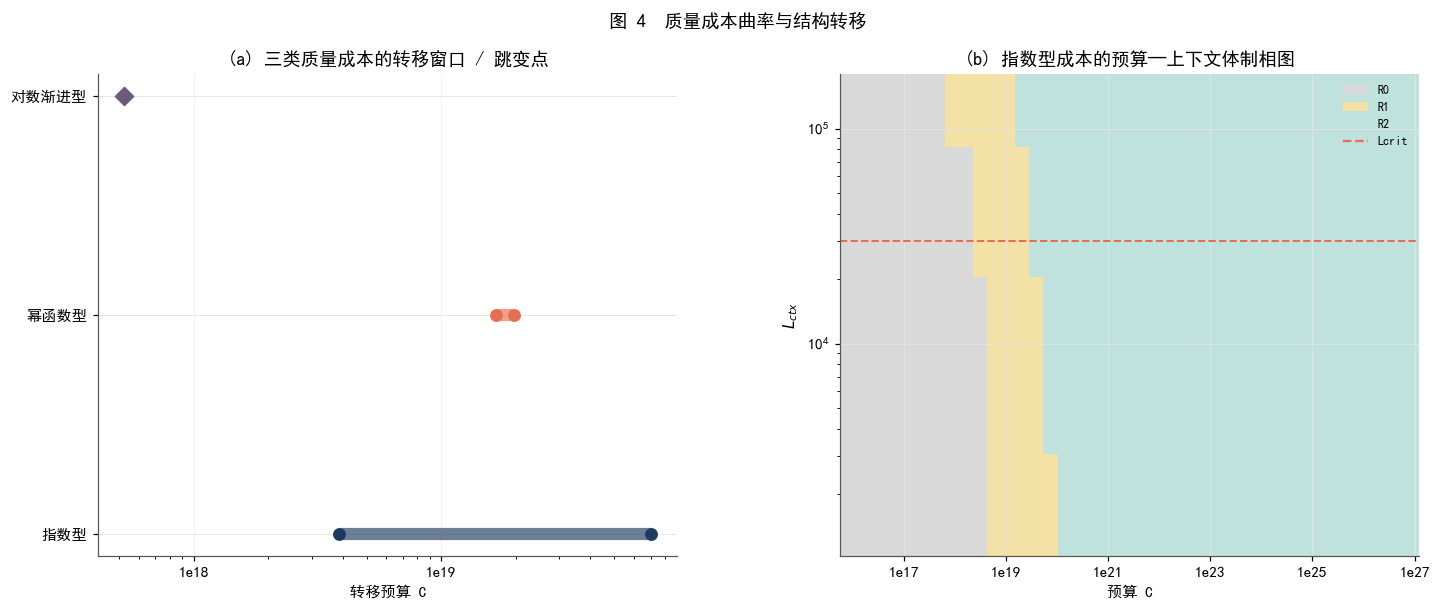

In [6]:
# ============ 5. 成本函数的转移窗口 + C×Lctx 相位图 ============
window_rows = []
for cost in COSTS:
    tr = (TRANS[TRANS['成本函数']==cost].sort_values('C_transition').reset_index(drop=True)
          if len(TRANS) else pd.DataFrame())
    if len(tr) == 0:
        window_rows.append({'成本函数':cost,'类型':'区间内无转移',
                            'C1':np.nan,'C2':np.nan,'C_jump':np.nan})
        continue
    same_recipe = all(r.from_p == r.to_p for r in tr.itertuples(index=False))
    simple_window = (
        len(tr) == 2 and same_recipe
        and tr.iloc[0].from_regime == 'R0' and tr.iloc[0].to_regime == 'R1'
        and tr.iloc[1].from_regime == 'R1' and tr.iloc[1].to_regime == 'R2'
        and tr.iloc[0].to_p == tr.iloc[1].from_p
    )
    simple_jump = (
        len(tr) == 1 and same_recipe
        and tr.iloc[0].from_regime == 'R0' and tr.iloc[0].to_regime == 'R2'
    )
    if simple_window:
        right = tr.iloc[1]
        if right.boundary_status == 'numerical_state_boundary':
            window_kind = 'R1 状态窗口（右端机制未证实）'
        elif 'branch value crossing' in right['定位机制']:
            window_kind = 'R1 分支交叉窗口'
        elif 'KKT rho(Q1)' in right['定位机制']:
            window_kind = 'R1 连续边界窗口'
        else:
            window_kind = 'R1 窗口（机制见转移表）'
        window_rows.append({
            '成本函数':cost,'类型':window_kind,
            'C1':float(tr.iloc[0].C_transition),
            'C2':float(right.C_transition),'C_jump':np.nan
        })
    elif simple_jump:
        window_rows.append({
            '成本函数':cost,'类型':'R0→R2 分支跳变',
            'C1':np.nan,'C2':np.nan,
            'C_jump':float(tr.iloc[0].C_transition)
        })
    else:
        # 含配比切换或多次转移时不存在可用单一窗口/跳变点概括的路径。
        window_rows.append({
            '成本函数':cost,'类型':'复合/配比转移；详见结构转移表',
            'C1':np.nan,'C2':np.nan,'C_jump':np.nan
        })
WINDOW = pd.DataFrame(window_rows)
WINDOW.to_csv(TAB/'transition_windows.csv',index=False,encoding='utf-8-sig')
display(WINDOW)

# 相位图
C_PHASE = np.logspace(16,27,41)
phase_rows = []
for L_ in FEAS:
    for C in C_PHASE:
        s = solve_executable(C,L_,'指数型',nscan=31)
        phase_rows.append({
            'L_ctx':L_,'C':C,'regime':s['regime'],
            'p_name':s['p_name'],'Q':s['Q'],'loss':s['loss'],
            'support_status':s['support_status'],'extrapolation_flag':s['extrapolation_flag']
        })
PH = pd.DataFrame(phase_rows)
PH.to_csv(TAB/'phase_map_exp.csv',index=False,encoding='utf-8-sig')

reg_map = {'R0':0,'R1':1,'R2':2}
Z = np.array([
    [reg_map[x] for x in PH[PH.L_ctx==L_].sort_values('C').regime]
    for L_ in FEAS
],float)

fig = plt.figure(figsize=(15.5,5.7))
gs = gridspec.GridSpec(1,2,wspace=.28)

ax = fig.add_subplot(gs[0])
for i,cost in enumerate(COSTS):
    r = WINDOW[WINDOW['成本函数']==cost].iloc[0]
    if np.isfinite(r.C1) and np.isfinite(r.C2):
        ax.hlines(i,r.C1,r.C2,color=COL_COST[cost],lw=8,alpha=.65)
        ax.scatter([r.C1,r.C2],[i,i],color=COL_COST[cost],s=55,zorder=3)
    elif np.isfinite(r.C_jump):
        ax.scatter(r.C_jump,i,marker='D',color=COL_COST[cost],s=70,zorder=3)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_yticks(range(len(COSTS))); ax.set_yticklabels(COSTS)
ax.set_xlabel('转移预算 C'); ax.set_title('(a) 三类质量成本的转移窗口 / 跳变点')
ax.grid(axis='x',alpha=.5)

ax = fig.add_subplot(gs[1])
X,Y = np.meshgrid(C_PHASE,np.array(FEAS,float))
cmap_reg = mpl.colors.ListedColormap([COL_REG['R0'],COL_REG['R1'],COL_REG['R2']])
norm_reg = mpl.colors.BoundaryNorm([-.5,.5,1.5,2.5],cmap_reg.N)
ax.pcolormesh(X,Y,Z,shading='nearest',cmap=cmap_reg,norm=norm_reg)
ax.axhline(L_CRIT,color=C_CORAL,ls='--',lw=1.3,label=f'Lcrit={L_CRIT:.0f}')
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel(r'$L_{ctx}$')
ax.set_title('(b) 指数型成本的预算—上下文体制相图')
ax.legend(handles=[
    Patch(facecolor=COL_REG['R0'],label='R0'),
    Patch(facecolor=COL_REG['R1'],label='R1'),
    Patch(facecolor=COL_REG['R2'],label='R2'),
    Line2D([0],[0],color=C_CORAL,ls='--',label='Lcrit')
],frameon=False,fontsize=8)

fig.suptitle('图 4  质量成本曲率与结构转移',fontsize=12)
savefig('fig04_transition_and_phase.png'); plt.show()


## 6. 上下文长度与资源响应

上下文长度通过 \(6+\eta_{\rm attn}L_{ctx}\) 改变每单位 \(ND\) 的计算成本，不直接改变当前设定的质量收益函数。代码在 C7 五个可行长度上重新优化，并另加入诊断长度 \(L_{ctx}^{\rm crit}=30000\)；后者是理论交叉点，不能称为 C7 实测可行值。

在 \(C=10^{19}\)、指数型成本下，已保存解从 \(L_{ctx}=2048\) 到 131072 的 \(Q_A^\star\) 由 0.773149 升至 0.992753，预测 Loss 由 3.03447 升至 3.32762，体制均为 R1。在 \(10^{22}\) 的六个长度上均为 R2；\(10^{24}\) 的结果带 `moderate_extrapolation` 或 `far_extrapolation` 标记。这些趋势是固定拟合参数与固定可执行配比下的模型预测。

跨预算响应以

\[
\varepsilon_N=\frac{d\ln N^\star}{d\ln C},\qquad
\varepsilon_D=\frac{d\ln D^\star}{d\ln C},\qquad
\varepsilon_Q=\frac{dQ_A^\star}{d\ln C}
\]

作数值描述。体制切换附近导数可能不连续，因此图中的尖峰不应解释为稳定的长期弹性，也不提供外推区间内的经验验证。


,L_ctx,C,p_star,N_B,D_B,Q_A,Loss,regime,s_train,s_attn,s_Q,support_status,extrapolation_flag
0,2048,1e+19,p_safe,0.307818,3.81531,0.776233,3.0127,R1,0.704651,0.0481042,0.247244,interpolation,False
1,2048,1e+22,p_safe,5.59985,253.027,1,2.08993,R2,0.850147,0.0580367,0.091816,interpolation,False
2,2048,1e+24,p_safe,40.7017,3780.57,1,1.88444,R2,0.923254,0.0630275,0.0137186,far_extrapolation,True
3,4096,1e+19,p_safe,0.303426,3.5957,0.786053,3.02336,R1,0.654617,0.089377,0.256006,interpolation,False
4,4096,1e+22,p_safe,5.42781,246.051,1,2.09355,R2,0.80131,0.109406,0.0892846,interpolation,False
5,4096,1e+24,p_safe,39.5583,3657.85,1,1.88628,R2,0.86819,0.118537,0.0132733,far_extrapolation,True
6,8192,1e+19,p_safe,0.294919,3.23851,0.803476,3.04292,R1,0.573059,0.156483,0.270458,interpolation,False
7,8192,1e+22,p_safe,5.1274,233.678,1,2.10029,R2,0.718898,0.196307,0.084795,interpolation,False
8,8192,1e+24,p_safe,37.5485,3443.06,1,1.88971,R2,0.775691,0.211815,0.0124939,far_extrapolation,True
9,30000,1e+19,p_safe,0.258324,2.21302,0.867739,3.12151,R1,0.343004,0.343004,0.313991,interpolation,False


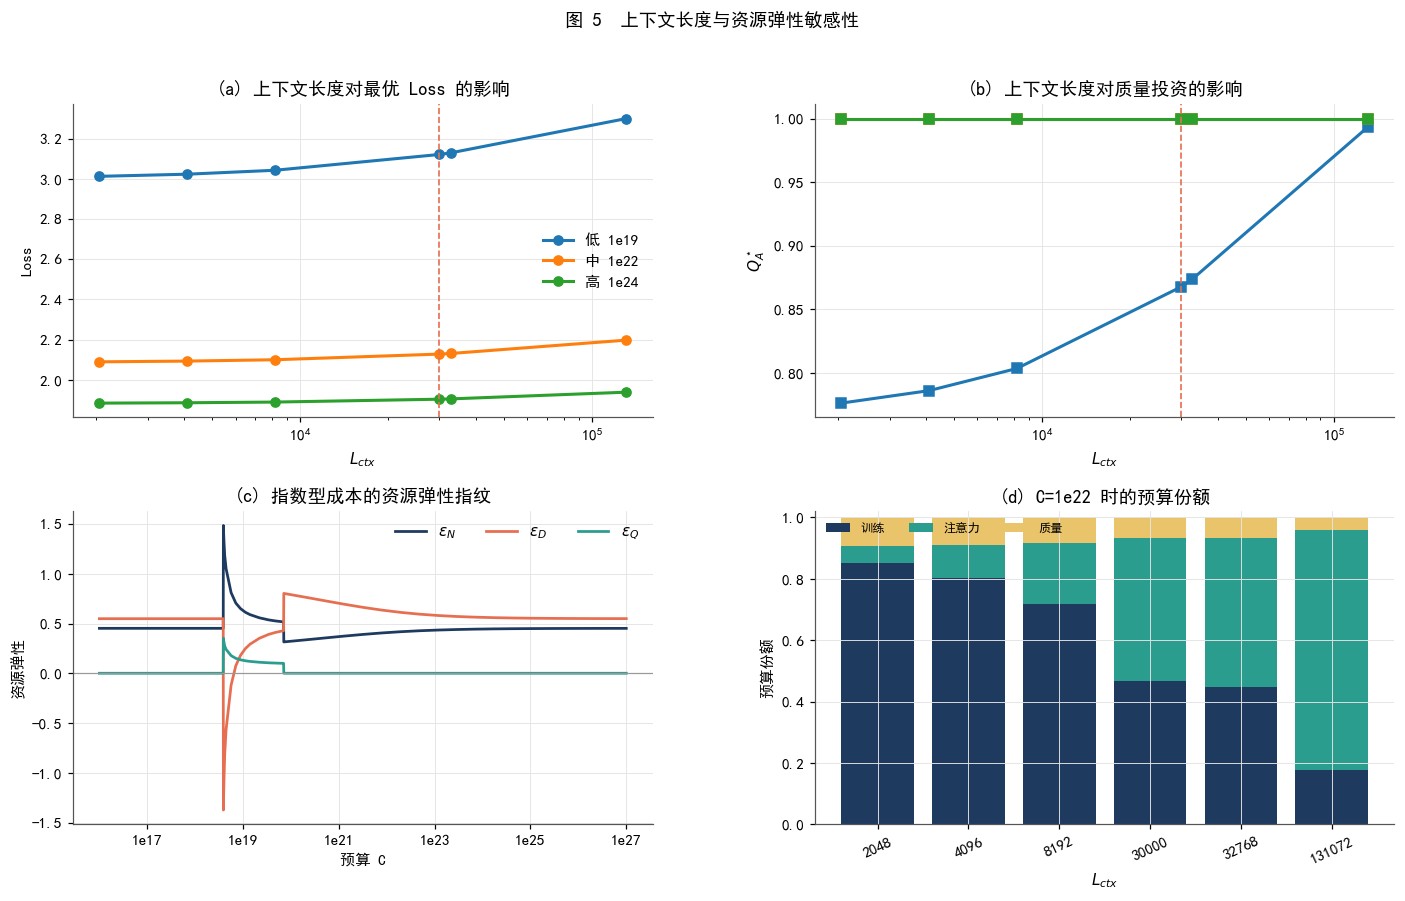

In [7]:
# ============ 6. Lctx 敏感性 + 资源弹性 ============
sens_rows = []
for L_ in L_ALL:
    for C in BUDGETS:
        s = solve_executable(C,L_,'指数型')
        sens_rows.append({
            'L_ctx':L_,'C':C,'p_star':s['p_name'],
            'N_B':s['N']/1e9,'D_B':s['D']/1e9,'Q_A':s['Q'],'Loss':s['loss'],
            'regime':s['regime'],'s_train':s['s_train'],'s_attn':s['s_attn'],'s_Q':s['s_Q'],
            'support_status':s['support_status'],'extrapolation_flag':s['extrapolation_flag']
        })
SENS_L = pd.DataFrame(sens_rows)
SENS_L.to_csv(TAB/'sensitivity_context_length.csv',index=False,encoding='utf-8-sig')
display(SENS_L)

cv = CURVES['指数型'].copy()
fig = plt.figure(figsize=(15.5,8.5))
gs = gridspec.GridSpec(2,2,wspace=.28,hspace=.30)

ax = fig.add_subplot(gs[0,0])
for C in BUDGETS:
    sub = SENS_L[SENS_L.C==C].sort_values('L_ctx')
    ax.plot(sub.L_ctx,sub.Loss,marker='o',lw=2,label=BUD_LAB[C])
ax.axvline(L_CRIT,color=C_CORAL,ls='--',lw=1.1)
ax.set_xscale('log'); ax.set_xlabel(r'$L_{ctx}$'); ax.set_ylabel('Loss')
ax.set_title('(a) 上下文长度对最优 Loss 的影响'); ax.legend(frameon=False)

ax = fig.add_subplot(gs[0,1])
for C in BUDGETS:
    sub = SENS_L[SENS_L.C==C].sort_values('L_ctx')
    ax.plot(sub.L_ctx,sub.Q_A,marker='s',lw=2,label=BUD_LAB[C])
ax.axvline(L_CRIT,color=C_CORAL,ls='--',lw=1.1)
ax.set_xscale('log'); ax.set_xlabel(r'$L_{ctx}$'); ax.set_ylabel(r'$Q_A^\star$')
ax.set_title('(b) 上下文长度对质量投资的影响')

ax = fig.add_subplot(gs[1,0])
ax.plot(cv.C,cv.eps_N,lw=1.8,color=C_NAVY,label=r'$\epsilon_N$')
ax.plot(cv.C,cv.eps_D,lw=1.8,color=C_CORAL,label=r'$\epsilon_D$')
ax.plot(cv.C,cv.eps_Q,lw=1.8,color=C_TEAL,label=r'$\epsilon_Q$')
ax.axhline(0,color='#999999',lw=.8)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('资源弹性')
ax.set_title('(c) 指数型成本的资源弹性指纹'); ax.legend(frameon=False,ncol=3)

ax = fig.add_subplot(gs[1,1])
sub = SENS_L[SENS_L.C==1e22].sort_values('L_ctx')
x = np.arange(len(sub))
ax.bar(x,sub.s_train,label='训练',color=C_NAVY)
ax.bar(x,sub.s_attn,bottom=sub.s_train,label='注意力',color=C_TEAL)
ax.bar(x,sub.s_Q,bottom=sub.s_train+sub.s_attn,label='质量',color=C_GOLD)
ax.set_xticks(x); ax.set_xticklabels([str(int(v)) for v in sub.L_ctx],rotation=25)
ax.set_ylim(0,1.02); ax.set_ylabel('预算份额'); ax.set_xlabel(r'$L_{ctx}$')
ax.set_title('(d) C=1e22 时的预算份额')
ax.legend(frameon=False,ncol=3,fontsize=8)

fig.suptitle('图 5  上下文长度与资源弹性敏感性',fontsize=12)
savefig('fig05_context_and_elasticity.png'); plt.show()


## 7. 条件不确定性与有限候选 minimax regret

### 7.1 本次实际覆盖的情景

问题二本次只导出了名义 \((E,A,\alpha,B,\beta)\) 参数组，没有完整的正性重标定 Scaling 场景。因此以下分析**不覆盖 Scaling Law 参数的联合不确定性**，也不能称为总体置信区间。

代码使用 \(\kappa\) 区间两端 \(0.4378,0.4873\)、质量桥 \(c_Q=0.75,1.25\)，以及五个人为尺度函数情景：无衰减 \(\gamma=0\)、局部幂衰减 \(\gamma=0.05,0.10\)、60M 后冻结衰减 \(\gamma=0.05,0.10\)。四类尺度衰减情景的参数都**未被估计**。这产生 \(2\times2\times5=20\) 个角点情景，另加一组名义情景，共 **21** 个。它们是质量桥与尺度形式的条件 stress test，不是采样得到的概率分布。

### 7.2 比较准则和搜索范围

对情景 \(s\)，令 \(L_s^\star\) 是该情景下可执行集合的模型最优值，比较候选决策 \(x\) 的相对 regret：

\[
r_s(x)=\frac{L_s(x)-L_s^\star}{\max(L_s^\star-E_s,10^{-12})}.
\]

算法从各情景的数值最优解和名义最优解组成**有限候选集**，选取其中 \(\max_s r_s(x)\) 最小者。因此输出名为 `minimax-regret candidate`，不是连续决策空间的全局 minimax 证明。

指数型成本下，\(10^{19}\) 的名义解与候选解最大 regret 都约为 0.008902；\(10^{22}\) 从约 \(1.19\times10^{-5}\) 降至 \(6.93\times10^{-6}\)，\(10^{24}\) 从约 \(8.37\times10^{-6}\) 降至 \(5.93\times10^{-6}\)。这些数值只适用于上述 21 个情景和当前候选集；\(10^{24}\) 仍是远距离外推。主推荐仍是名义、可执行的 \(p_{\rm risk}\) 条件解。


敏感性覆盖范围: quality_bridge_x_structural_scale_scenarios__full_scaling_not_exported
完整 Scaling 参数组: ['nominal']
尺度函数情景（未识别时均为人为设定）: [{'form': 'local-power', 'gamma': 0.05, 'estimated': False}, {'form': 'frozen-after-60M', 'gamma': 0.05, 'estimated': False}, {'form': 'local-power', 'gamma': 0.1, 'estimated': False}, {'form': 'frozen-after-60M', 'gamma': 0.1, 'estimated': False}, {'form': 'no-attenuation', 'gamma': 0.0, 'estimated': False}]
联合情景数量: 21


,C,方法,p,Q,max_regret,mean_regret,uncertainty_scope
0,1e+19,nominal executable,p_safe,0.786053,0.00858048,0.00495044,quality_bridge_x_structural_scale_scenarios__f...
1,1e+19,minimax-regret candidate,p_safe,0.786053,0.00858048,0.00495044,quality_bridge_x_structural_scale_scenarios__f...
2,1e+22,nominal executable,p_safe,1,4.05268e-06,1.22381e-06,quality_bridge_x_structural_scale_scenarios__f...
3,1e+22,minimax-regret candidate,p_safe,1,2.37197e-06,1.51089e-06,quality_bridge_x_structural_scale_scenarios__f...
4,1e+24,nominal executable,p_safe,1,2.83995e-06,9.26894e-07,quality_bridge_x_structural_scale_scenarios__f...
5,1e+24,minimax-regret candidate,p_safe,1,2.02588e-06,1.26714e-06,quality_bridge_x_structural_scale_scenarios__f...


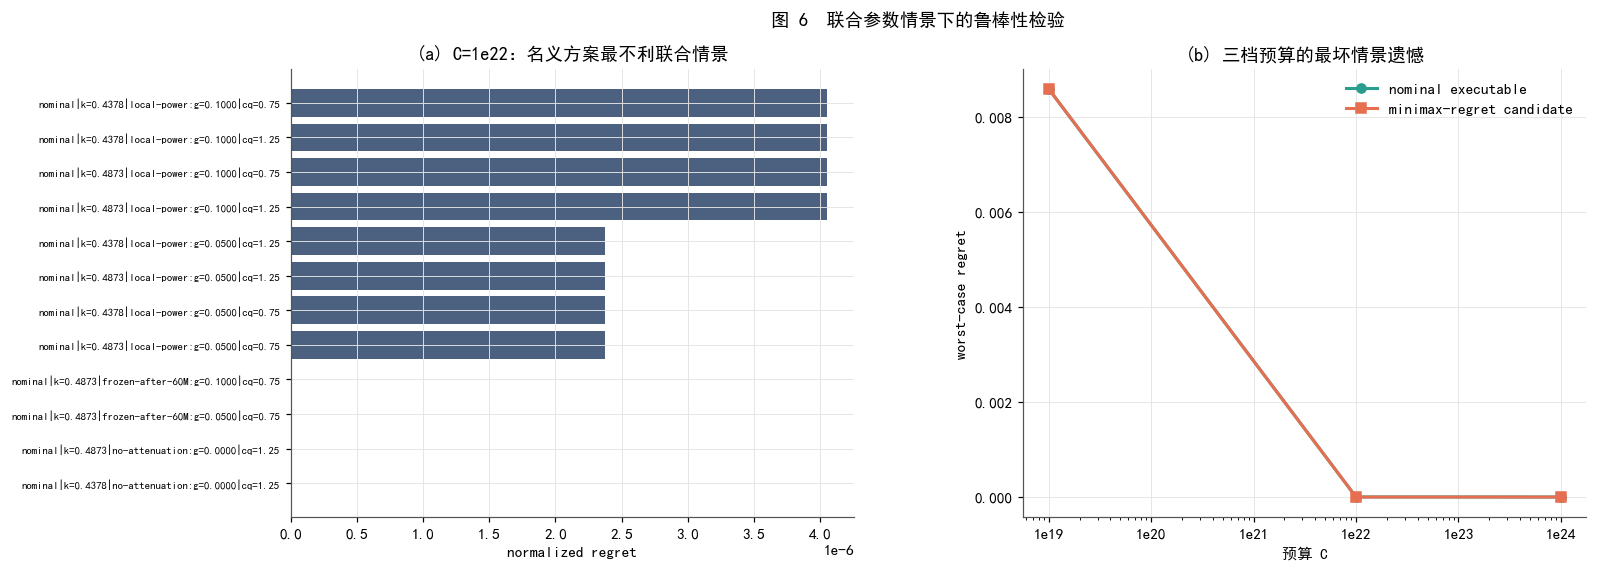

In [8]:
# ============ 7. 联合不确定性情景 + minimax-regret ============
REQ_TH = {'E','A','alpha','B','beta'}

def collect_full_scaling_scenarios():
    found = {}

    def scan(obj,prefix=''):
        if isinstance(obj,dict):
            if REQ_TH.issubset(obj.keys()):
                try:
                    th = {k:float(obj[k]) for k in REQ_TH}
                    if th['E']>=0 and th['A']>0 and th['B']>0 and th['alpha']>0 and th['beta']>0:
                        found[prefix or 'scenario'] = th
                except Exception:
                    pass
            for k,v in obj.items():
                if k in {'scaling_scenarios','exponent_scenarios','scenarios'} or isinstance(v,dict):
                    scan(v,f'{prefix}.{k}' if prefix else str(k))

    # 先扫 Q2 handoff
    scan(Q2)

    # 再扫 sidecar（如果问题二后来补导出）
    for fn in ['scaling_scenarios.json','exponent_scenarios.json','positive_recalibrated_scaling_scenarios.json']:
        p = Q2_TABLE/fn
        if p.exists():
            try:
                scan(json.loads(p.read_text(encoding='utf-8')),fn)
            except Exception:
                pass

    # 去掉与 nominal 几乎相同的重复场景
    uniq = {'nominal':TH}
    sigs = {tuple(round(TH[k],12) for k in ('E','A','alpha','B','beta'))}
    for name,th in found.items():
        sig = tuple(round(th[k],12) for k in ('E','A','alpha','B','beta'))
        if sig not in sigs:
            sigs.add(sig); uniq[name]=th
    return uniq

SCALING_SCEN = collect_full_scaling_scenarios()
HAS_FULL_SCALING_UNC = len(SCALING_SCEN) > 1

k_vals = sorted(set([float(KAPPA_CI[0]),float(KAPPA_CI[1])]))
cq_vals = sorted(set([float(min(CQ_SCENARIOS)),float(max(CQ_SCENARIOS))]))

SCENARIOS = []
for th_name,ths in SCALING_SCEN.items():
    for kv,cqv,scale in itertools.product(k_vals,cq_vals,SCALE_SCENARIOS):
        gv,form = scale['gamma'],scale['form']
        SCENARIOS.append({
            'name':f'{th_name}|k={kv:.4f}|{form}:g={gv:.4f}|cq={cqv:.2f}',
            'th_name':th_name,'th':ths,'kappa':kv,'gamma':gv,'c_q':cqv,
            'scale_form':form,'gamma_estimated':bool(scale['estimated'])
        })

SCENARIOS.append({
    'name':'nominal','th_name':'nominal','th':TH,
    'kappa':KAPPA,'gamma':GAMMA_P,'c_q':CQ_NOMINAL,
    'scale_form':SCALE_FORM_NOMINAL,'gamma_estimated':GAMMA_IDENTIFIED
})
assert len({sc['name'] for sc in SCENARIOS}) == len(SCENARIOS)

UNCERTAINTY_SCOPE = (
    'full_scaling_x_quality_bridge_x_structural_scale_scenarios'
    if HAS_FULL_SCALING_UNC
    else 'quality_bridge_x_structural_scale_scenarios__full_scaling_not_exported'
)

print('敏感性覆盖范围:',UNCERTAINTY_SCOPE)
print('完整 Scaling 参数组:',list(SCALING_SCEN.keys()))
print('尺度函数情景（未识别时均为人为设定）:',SCALE_SCENARIOS)
print('联合情景数量:',len(SCENARIOS))
if not HAS_FULL_SCALING_UNC:
    warnings.warn(
        '问题二当前 handoff 未导出完整的正性重标定 Scaling 场景。'
        '本节只做质量参数/坐标桥与配比尺度函数的条件 stress test；'
        '不把结果表述为完整 Scaling Law 鲁棒性。'
    )

def eval_decision(x,sc):
    return float(L_gen(
        x['N'],x['D'],x['Q'],x['Q0_A'],
        th=sc['th'],kappa=sc['kappa'],psi_p0=x['psi_p0'],
        gamma=sc['gamma'],c_q=sc['c_q'],scale_form=sc['scale_form']
    ))

def robust_minimax_regret(C,L,cost):
    scen_opt = []
    for sc in SCENARIOS:
        z = solve_executable(
            C,L,cost,th=sc['th'],kappa=sc['kappa'],
            gamma=sc['gamma'],c_q=sc['c_q'],scale_form=sc['scale_form'],nscan=71
        )
        z['scenario_origin'] = sc['name']
        scen_opt.append(z)

    nominal = solve_executable(C,L,cost)
    candidates = scen_opt + [dict(nominal,scenario_origin='nominal_solution')]

    optloss = {z['scenario_origin']:z['loss'] for z in scen_opt}
    # 场景可能同名 nominal；用顺序重新建立
    scenario_opt_loss = {
        sc['name']: next(z['loss'] for z in scen_opt if z['scenario_origin']==sc['name'])
        for sc in SCENARIOS
    }

    rows = []
    for j,x in enumerate(candidates):
        regrets = []
        for sc in SCENARIOS:
            ls = eval_decision(x,sc)
            lstar = scenario_opt_loss[sc['name']]
            denom = max(lstar - sc['th']['E'],1e-12)
            regrets.append((ls-lstar)/denom)
        rows.append({
            'idx':j,'max_regret':max(regrets),'mean_regret':float(np.mean(regrets)),
            'regrets':regrets
        })

    best = min(rows,key=lambda r:(r['max_regret'],r['mean_regret']))
    x = candidates[best['idx']].copy()
    x.update({
        'max_regret':best['max_regret'],'mean_regret':best['mean_regret'],
        'uncertainty_scope':UNCERTAINTY_SCOPE
    })
    return x,scen_opt

ROB_ROWS = []
for C in BUDGETS:
    rob,opts = robust_minimax_regret(C,L_DEFAULT,'指数型')
    nom = solve_executable(C,L_DEFAULT,'指数型')

    # 名义解在所有情景的 regret
    scene_opt_loss = {
        sc['name']: next(z['loss'] for z in opts if z['scenario_origin']==sc['name'])
        for sc in SCENARIOS
    }
    regs = []
    for sc in SCENARIOS:
        ls = eval_decision(nom,sc)
        denom = max(scene_opt_loss[sc['name']]-sc['th']['E'],1e-12)
        regs.append((ls-scene_opt_loss[sc['name']])/denom)

    ROB_ROWS.append({
        'C':C,'方法':'nominal executable','p':nom['p_name'],'Q':nom['Q'],
        'max_regret':max(regs),'mean_regret':float(np.mean(regs)),
        'uncertainty_scope':UNCERTAINTY_SCOPE
    })
    ROB_ROWS.append({
        'C':C,'方法':'minimax-regret candidate','p':rob['p_name'],'Q':rob['Q'],
        'max_regret':rob['max_regret'],'mean_regret':rob['mean_regret'],
        'uncertainty_scope':UNCERTAINTY_SCOPE
    })

ROB = pd.DataFrame(ROB_ROWS)
ROB.to_csv(TAB/'joint_uncertainty_minimax_regret.csv',index=False,encoding='utf-8-sig')
display(ROB)

# 图 6：原版风格 horizontal bar + budget comparison
fig = plt.figure(figsize=(15.2,5.3))
gs = gridspec.GridSpec(1,2,wspace=.30)

ax = fig.add_subplot(gs[0])
midC = 1e22
rob_mid,opts_mid = robust_minimax_regret(midC,L_DEFAULT,'指数型')
nom_mid = solve_executable(midC,L_DEFAULT,'指数型')
scene_opt_loss = {
    sc['name']: next(z['loss'] for z in opts_mid if z['scenario_origin']==sc['name'])
    for sc in SCENARIOS
}
vals = []
labs = []
for sc in SCENARIOS:
    denom = max(scene_opt_loss[sc['name']]-sc['th']['E'],1e-12)
    vals.append((eval_decision(nom_mid,sc)-scene_opt_loss[sc['name']])/denom)
    labs.append(sc['name'])
order = np.argsort(vals)
show = order[-min(12,len(order)):]
ax.barh(np.arange(len(show)),np.array(vals)[show],color=C_NAVY,alpha=.80)
ax.set_yticks(np.arange(len(show)))
ax.set_yticklabels(np.array(labs,dtype=object)[show],fontsize=7)
ax.set_xlabel('normalized regret')
ax.set_title('(a) C=1e22：名义方案最不利联合情景')

ax = fig.add_subplot(gs[1])
for method,color,marker in [
    ('nominal executable',C_TEAL,'o'),
    ('minimax-regret candidate',C_CORAL,'s')
]:
    sub = ROB[ROB['方法']==method].sort_values('C')
    ax.plot(sub.C,sub.max_regret,marker=marker,lw=2,color=color,label=method)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('worst-case regret')
ax.set_title('(b) 三档预算的最坏情景遗憾')
ax.legend(frameon=False)

fig.suptitle('图 6  联合参数情景下的鲁棒性检验',fontsize=12)
savefig('fig06_joint_uncertainty.png'); plt.show()


## 8. 逻辑证书、等效算力与问题四接口

已保存的 `logic_consistency_certificate.json` 记录：`reference_excluded=true`、`quality_neutrality=true`、`p_rob_alias_removed=true`；可执行角色只有 `p_risk`，配置范围为 `fixed_p_risk_conditional_N_D_Q`，`gamma_p_identified=false`，主尺度形式为 `no-attenuation`，`full_scaling_scenarios_available=false`。这些字段核对代码口径，不能替代参数识别、外部预测验证或全局最优性证明。

“等效算力倍数”令反事实模型固定 \(Q_A=Q_{0,A}\)，并仅在同一可执行集合中选择配比。若其预算 \(C_{eq}\) 才达到完整质量治理模型在预算 \(C\) 下的**预测** Loss，则定义

\[
M(C)=C_{eq}/C.
\]

三档预算的已保存结果：指数型 \(M\approx1.074,2.566,2.799\)；幂函数型 \(1.000,2.525,2.792\)；对数渐进型 \(1.871,2.767,2.828\)。它衡量模型内追加治理与扩张算力的替代关系，并非真实训练中的因果增益；\(10^{24}\) 的三个倍数都处于远距离外推。代码输出日志显示问题四接口 `output_q3_revised/tables/q3_outputs_for_q4.json` 已写出；其后续使用仍须保留配比、尺度识别与支撑域标记。


In [9]:
# ============ 8. 逻辑证书 + 等效算力 + 问题四接口 ============
def solve_no_quality(C,L,cost,th=None,kappa=None,eta=None,gamma=None,c_q=None,scale_form=None):
    """强制 Q=Q0；由于相对质量因子=1，baseline 性能只由配比结构项决定。"""
    results = []
    for p_name,info in EXEC_INFO.items():
        s = _fixedQ_kkt(
            C,L,cost,info['Q0_A'],info['Q0_A'],
            th,kappa,info['psi_p0'],eta,gamma=gamma,c_q=c_q,scale_form=scale_form
        )
        s.update({'p_name':p_name,'Q0_A':info['Q0_A'],'psi_p0':info['psi_p0']})
        results.append(s)
    return min(results,key=lambda z:z['loss']).copy()

def equivalent_compute_multiplier(C,L,cost):
    target = solve_executable(C,L,cost)['loss']
    def f(lc):
        return solve_no_quality(10**lc,L,cost)['loss'] - target
    lo = np.log10(C)
    if f(lo) <= 0:
        return 1.0,C
    hi = lo + .5
    while hi < 35 and f(hi) > 0:
        hi += .5
    if hi >= 35 and f(hi) > 0:
        return np.nan,np.nan
    root = brentq(f,lo,hi,xtol=1e-8,rtol=1e-9)
    Ceq = 10**root
    return Ceq/C,Ceq

EQ_ROWS = []
for cost in COSTS:
    for C in BUDGETS:
        M,Ceq = equivalent_compute_multiplier(C,L_DEFAULT,cost)
        EQ_ROWS.append({'成本函数':cost,'C':C,'M':M,'C_eq':Ceq,
                        'support_status':solve_executable(C,L_DEFAULT,cost)['support_status']})
EQ = pd.DataFrame(EQ_ROWS)
EQ.to_csv(TAB/'equivalent_compute_multiplier.csv',index=False,encoding='utf-8-sig')
display(EQ)

CERT_ROWS = []
for C in BUDGETS:
    s = solve_executable(C,L_DEFAULT,'指数型')
    CERT_ROWS.append({
        'C':C,'p_star':s['p_name'],'regime':s['regime'],
        'budget_resid':s['budget_resid'],
        'N_KKT_logresid':s['N_kkt_logresid'],
        'N_stationarity_status':s['N_stationarity_status'],
        'Q_KKT_violation':s['Q_kkt_violation'],
        'certificate':s['certificate'],
        'support_status':s['support_status'],'extrapolation_flag':s['extrapolation_flag']
    })
CERT = pd.DataFrame(CERT_ROWS)
CERT.to_csv(TAB/'solver_certificates.csv',index=False,encoding='utf-8-sig')

LOGIC_CERT = {
    'reference_excluded': bool('p_ref' not in EXEC_INFO),
    'quality_neutrality': bool(np.allclose(QUALITY_NEUTRALITY.psiQ_rel_at_Q0,1.0,atol=1e-12)),
    'p_rob_alias_removed': True,
    'uncertainty_scope': UNCERTAINTY_SCOPE,
    'full_scaling_scenarios_available': bool(HAS_FULL_SCALING_UNC),
    'executable_roles': list(EXEC_INFO.keys()),
    'reference_role': 'normalization reference / theoretical oracle',
    'allocation_scope':ALLOCATION_SCOPE,
    'gamma_p_identified':GAMMA_IDENTIFIED,
    'nominal_scale_form':SCALE_FORM_NOMINAL,
    'support_basis':'B1 marginal N, D, 6ND range; moderate threshold=10x; not joint Q/p validation'
}
json.dump(LOGIC_CERT,open(TAB/'logic_consistency_certificate.json','w',encoding='utf-8'),
          ensure_ascii=False,indent=2)

def clean_dict(d,keep=None):
    if keep is not None:
        d = {k:d[k] for k in keep if k in d}
    out = {}
    for k,v in d.items():
        if isinstance(v,(np.floating,np.integer)):
            out[k] = float(v)
        elif isinstance(v,(str,bool,int,float)) or v is None:
            out[k] = v
    return out

optimal_configs = {}
for C in BUDGETS:
    key = f'{C:.0e}'
    optimal_configs[key] = {}
    for cost in COSTS:
        s = solve_executable(C,L_DEFAULT,cost)
        o = solve_reference_oracle(C,L_DEFAULT,cost)
        fields = [
            'N','D','Q','Q_B','loss','regime','p_name','Q0_A','psi_p0','psi_p_N',
            'gamma_p','gamma_p_identified','scale_form','c_Q','s_train','s_attn','s_Q','certificate',
            'support_status','extrapolation_flag','N_stationarity_status'
        ]
        optimal_configs[key][cost] = {
            'executable':clean_dict(s,fields),
            'theoretical_reference':clean_dict(o,fields),
            'evidence_gap':float(s['loss']-o['loss'])
        }

handoff = {
    'method':'evidence_constrained_SAED_compute_allocation',
    'source_q2_model':Q2.get('model_name','SAED-Modular-Separable'),
    'quality_factor':'psi_Q_abs(Q_A)/psi_Q_abs(Q0_A(p))',
    'inputs':{
        'classic_law':TH,
        'kappa':KAPPA,'kappa_ci':KAPPA_CI,
        'gamma_p_identified':GAMMA_IDENTIFIED,
         'gamma_p_local':GAMMA_P if GAMMA_IDENTIFIED else None,
         'gamma_p_bootstrap':GAMMA_CI if GAMMA_IDENTIFIED else None,
         'gamma_p_nominal':GAMMA_P,
         'gamma_sensitivity_values':GAMMA_SENSITIVITY_VALUES,
         'scale_scenarios':SCALE_SCENARIOS,
         'nominal_scale_form':SCALE_FORM_NOMINAL,
        'quality_bridge_nominal_c_Q':CQ_NOMINAL,
        'quality_bridge_scenarios':CQ_SCENARIOS,
        'eta':ETA,'L_crit':L_CRIT,
        'L_feasible_C7':FEAS,'L_default':L_DEFAULT,
        'cost_functions':G_PAR
    },
    'mixture_role_ledger':ROLE_TABLE.to_dict(orient='records'),
    'allocation_scope':ALLOCATION_SCOPE,
    'support_status_definition':{
        'reference_dataset':'B1 Pythia checkpoints',
        'rule':'interpolation means inside marginal N/D/6ND ranges; moderate within 10x upper and 0.1x lower; otherwise far',
        'scope':'scale-coordinate heuristic only; Q/p transfer and large models are not independently validated',
        'B1_limits':B1_LIMITS
    },
    'logic_certificate':LOGIC_CERT,
    'optimal_configs_default_Lctx':optimal_configs,
    'transitions_default_Lctx':TRANS.to_dict(orient='records'),
    'context_sensitivity':SENS_L.to_dict(orient='records'),
    'joint_uncertainty_regret':ROB.to_dict(orient='records'),
    'equivalent_compute':EQ.to_dict(orient='records'),
    'solver_certificates':CERT.to_dict(orient='records'),
    'notes':(
        'p_ref is never an executable candidate. Q0_A(p) is a quality-governance starting point and cost baseline; '
        'baseline performance at Q=Q0 is neutralized through a relative quality factor. '
        'When only p_risk is formally exported, optimization is conditional on fixed p_risk. '
        'Gamma/scale-form alternatives are structural sensitivity, not a confidence interval. '
        'High-budget configurations are conditional extrapolations; full scaling robustness requires complete positive-recalibrated scenarios from Q2.'
    )
}
json.dump(handoff,open(TAB/'q3_outputs_for_q4.json','w',encoding='utf-8'),
          ensure_ascii=False,indent=2,default=float)

print('逻辑一致性证书：')
print(json.dumps(LOGIC_CERT,ensure_ascii=False,indent=2))
print('\n已保存:',TAB/'q3_outputs_for_q4.json')


,成本函数,C,M,C_eq,support_status
0,指数型,1e+19,1.0829,1.0829e+19,interpolation
1,指数型,1e+22,2.59988,2.59988e+22,interpolation
2,指数型,1e+24,2.83635,2.83635e+24,far_extrapolation
3,幂函数型,1e+19,1,1e+19,interpolation
4,幂函数型,1e+22,2.55769,2.55769e+22,interpolation
5,幂函数型,1e+24,2.82962,2.82962e+24,far_extrapolation
6,对数渐进型,1e+19,1.88557,1.88557e+19,interpolation
7,对数渐进型,1e+22,2.8033,2.8033e+22,interpolation
8,对数渐进型,1e+24,2.86569,2.86569e+24,far_extrapolation


逻辑一致性证书：
{
  "reference_excluded": true,
  "quality_neutrality": true,
  "p_rob_alias_removed": true,
  "uncertainty_scope": "quality_bridge_x_structural_scale_scenarios__full_scaling_not_exported",
  "full_scaling_scenarios_available": false,
  "executable_roles": [
    "p_risk",
    "p_safe",
    "p_measured"
  ],
  "reference_role": "normalization reference / theoretical oracle",
  "allocation_scope": "finite_executable_recipe_selection_with_conditional_N_D_Q",
  "gamma_p_identified": false,
  "nominal_scale_form": "no-attenuation",
  "support_basis": "B1 marginal N, D, 6ND range; moderate threshold=10x; not joint Q/p validation"
}

已保存: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\output_q3_revised\tables\q3_outputs_for_q4.json


## 9. 结论口径与文件清单

### 9.1 本次可以成立的结论

在读取到的问题一、二接口及固定名义参数下，本次实际优化 \(p_{\rm risk}\) 的 \(N,D,Q_A\)，使用

\[
L=E+(AN^{-\alpha}+BD^{-\beta})
\frac{\psi_Q^{\rm abs}(Q_A)}{\psi_Q^{\rm abs}(Q_{0,A}(p_{\rm risk}))}
\psi_p(p_{\rm risk},N).
\]

相对因子在 \(Q_A=Q_{0,A}\) 时等于 1，使领域均值质量不被当作第二条配比性能通道。主结果采用 \(\gamma_p=0\) 的**无衰减结构零假设**，不能说已估得配比效应会随规模消退。这里计算成本的 \(\eta_{\rm attn}=2\times10^{-4}\) 与问题一讨论的质量效应记号含义不同。

默认上下文长度下，指数型成本在三档预算依次为 R1、R2、R2；幂函数型为 R0、R2、R2；对数渐进型始终为 R2。连续预算表中，指数型和幂函数型的 R0→R1 是 KKT 边界条件根，两处 R1→R2 是**KKT 未证实的数值状态边界**；对数渐进型 R0→R2 是端点分支等值根。上述结果描述模型解，不代表真实大模型训练已经复现相同转移。

\(p_{\rm ref}\) 只是不可执行的比较解；与 \(p_{\rm risk}\) 的 Loss 差值是模型内预测差值。鲁棒结果仅覆盖 21 个质量桥与人为尺度情景，并只在有限候选集上计算 minimax regret。\(10^{24}\) 的三类成本主结果均被标记为远距离外推；`interpolation` 也只检查 B1 的 \(N,D,6ND\) 边际范围。这些限制应随问题四接口一同传递。

### 9.2 输出清单

图：`fig01_inputs_and_roles.png`、`fig02_three_budget_executable.png`、`fig03_budget_continuation.png`、`fig04_transition_and_phase.png`、`fig05_context_and_elasticity.png`、`fig06_joint_uncertainty.png`。

表与接口：`mixture_role_ledger.csv`、`optimal_executable_allocation_three_budgets.csv`、`budget_continuation_*.csv`、`structural_transition_points.csv`、`transition_windows.csv`、`phase_map_exp.csv`、`sensitivity_context_length.csv`、`joint_uncertainty_minimax_regret.csv`、`equivalent_compute_multiplier.csv`、`solver_certificates.csv`、`logic_consistency_certificate.json`、`q3_outputs_for_q4.json`。文件路径均相对于 `output_q3_revised/` 的 `figures/` 或 `tables/`。

### 背景文献

[Hoffmann et al., *Training Compute-Optimal Large Language Models*, NeurIPS 2022](https://proceedings.neurips.cc/paper_files/paper/2022/file/c1e2faff6f588870935f114ebe04a3e5-Paper-Conference.pdf)；[Xie et al., *DoReMi*, NeurIPS 2023](https://papers.neurips.cc/paper_files/paper/2023/hash/dcba6be91359358c2355cd920da3fcbd-Abstract-Conference.html)；[Muennighoff et al., *Scaling Data-Constrained Language Models*, NeurIPS 2023](https://proceedings.neurips.cc/paper_files/paper/2023/hash/9d89448b63ce1e2e8dc7af72c984c196-Abstract-Conference.html)；[Li et al., *DataComp-LM*, NeurIPS 2024](https://proceedings.neurips.cc/paper_files/paper/2024/file/19e4ea30dded58259665db375885e412-Paper-Datasets_and_Benchmarks_Track.pdf)；[Liu et al., *RegMix*, ICLR 2025](https://proceedings.iclr.cc/paper_files/paper/2025/hash/5f67d864aae6115374fed7beddd119e0-Abstract-Conference.html)。这些文献提供背景；本 notebook 的具体数值结论来自前两问接口与本次保存的模型运行结果，不能归因于上述文献。
